SI Acknowledgement: SI was used for data searching, cross-checking, and to draft and debug the code in this journal. Outputs are human-verified.

# Case 5: the Thunder Bay 36 wildfire seen by NISAR radar (northwestern Ontario, July 2026)

NISAR is the new NASA and ISRO radar satellite. Its L-band radar (24 cm wavelength) goes through smoke and clouds and reaches into the forest canopy. In this case we use it to map **where the boreal forest canopy burned** in the Thunder Bay 36 fire, the largest wildfire ever recorded in Ontario, around Wabakimi Provincial Park.

The method is the one of case 3 (Bald Range wildfire, British Columbia), applied to a fire about twelve times larger, in flat boreal forest.

This notebook, read from top to bottom:

1. **Study area**: where the fire burned, on a satellite photo, with the official fire perimeter and the communities it reached.
2. **Data**: which NISAR files, and how we fetch them with NASA's API.
3. **The raw radar**: before and after the fire, and how we clean the speckle.
4. **What a fire does to the echo**: canopy loss, and what else can change the radar.
5. **Thresholds**: relative change, and the numbers chosen from the data.
6. **The rules and their map**: canopy loss and severe canopy loss.
7. **Validation**: against the official fire perimeter and the Sentinel-2 burn severity.
8. **Time series**: canopy loss on every pass, and the satellite fire detections that date it.
9. **Export** of the case study for the app, in the team's standard format.

The main radar channel is **HV** (explained in section 2): it measures the forest canopy, so it drops where the canopy burned.

In [1]:
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  (adds the .rio tools to xarray)
import xarray as xr
from matplotlib.patches import Patch
from pyproj import Transformer
from rasterio.features import geometry_mask
from scipy import ndimage

DATA = Path("../data/case5")      # this notebook lives in dataScience/notebooks/
CACHE = DATA / "cache"            # downloads (large, not committed to git)
EXPORT = DATA / "export"          # the case study for the app (small, committed), copied to application/public/assets/geospatial/case5/
CACHE.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)
PIXEL_M = 40                      # analysis pixel size (metres): the fire is large, 40 m keeps the data light

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

### Map helpers

The study area gets one grid: 40 m pixels in UTM zone 16N, covering the study box. Every radar date and every photo is resampled onto it, so pixel `[row, col]` is the same spot on the ground in every image. Case 3 used 20 m pixels; this fire is about twelve times larger, and 40 m pixels (0.16 ha) are still fine to map a burn of 3,000 km².

In [2]:
def make_grid(bbox, epsg, res=None):
    """Empty grid (UTM) that covers the lon/lat box, with square pixels of `res` metres."""
    res = res or PIXEL_M
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x0, x1 = np.floor(min(xs) / res) * res, np.ceil(max(xs) / res) * res
    y0, y1 = np.floor(min(ys) / res) * res, np.ceil(max(ys) / res) * res
    x = np.arange(x0 + res / 2, x1, res)
    y = np.arange(y1 - res / 2, y0, -res)
    return xr.DataArray(np.zeros((y.size, x.size), "float32"), coords={"y": y, "x": x}, dims=("y", "x")).rio.write_crs(epsg)


def extent(grid):
    h = PIXEL_M / 2
    return [float(grid.x[0]) - h, float(grid.x[-1]) + h, float(grid.y[-1]) - h, float(grid.y[0]) + h]


def lonlat_to_grid(grid, lon, lat):
    return Transformer.from_crs(4326, grid.rio.crs, always_xy=True).transform(lon, lat)


def box_xy(grid, w, s, e, n):
    """Outline of a lon/lat box in grid coordinates (for drawing)."""
    return lonlat_to_grid(grid, [w, e, e, w, w], [s, s, n, n, s])


def zoom_to(ax, grid, w, s, e, n):
    xs, ys = box_xy(grid, w, s, e, n)
    ax.set_xlim(min(xs), max(xs))
    ax.set_ylim(min(ys), max(ys))


def scale_bar(ax, km=10):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="white", lw=3)
    ax.text(x + km * 500, y + 0.015 * (y1 - y0), f"{km} km", color="white", ha="center", fontsize=8)


def clean_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")


def show_radar(ax, grid, db, title, vmin=-25, vmax=-5):
    """Grey radar image in dB: dark = little echo, bright = strong echo."""
    im = ax.imshow(db, cmap="gray", vmin=vmin, vmax=vmax, extent=extent(grid), interpolation="nearest")
    clean_axes(ax, title)
    return im


def show_classes(ax, grid, codes, colors):
    """Colour the pixels whose code is in `colors` ({code: hex}); others stay transparent."""
    rgba = np.zeros(codes.shape + (4,), "uint8")
    for k, hexcol in colors.items():
        rgba[codes == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    ax.imshow(rgba, extent=extent(grid), interpolation="nearest")


def draw_outline(ax, gdf, grid, color="#ff7f00", lw=1.6, label=None):
    """Draw polygon outlines (for example the official fire perimeter) on a grid map."""
    for geom in gdf.to_crs(grid.rio.crs).geometry:
        for poly in getattr(geom, "geoms", [geom]):
            ax.plot(*poly.exterior.xy, color=color, lw=lw, label=label)
            label = None


def inside_mask(gdf, grid):
    """True on the grid pixels inside the polygons."""
    if len(gdf) == 0:
        return np.zeros(grid.shape, bool)
    return ~geometry_mask(gdf.to_crs(grid.rio.crs).geometry, out_shape=grid.shape, transform=grid.rio.transform())

### Data helpers

Five public sources, each cached in `data/case5/cache/` after the first download:
- **NISAR** radar files from NASA Earthdata (free account, password in `~/.netrc`). We read **only the pixels of the study box** from each 4 to 7 GB file, in strips, averaged to 40 m right away.
- **Sentinel-2** photos from the free **Earth Search** catalogue (no login).
- The official **fire perimeters** of the Ontario Ministry of Natural Resources ("In-year Fire Perimeters", Land Information Ontario, public).
- The **satellite fire detections** (hotspots) of the Canadian Wildland Fire Information System (Natural Resources Canada, public).
- **Place names** from the Canadian Geographical Names Database (Natural Resources Canada, public).

In [3]:
STAC = "https://earth-search.aws.element84.com/v1/search"


def stac_search(collection, bbox, day):
    """Images of one collection that touch the box on one day (public STAC API)."""
    body = {"collections": [collection], "bbox": list(bbox), "limit": 20,
            "datetime": f"{day}T00:00:00Z/{day}T23:59:59Z"}
    req = urllib.request.Request(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=120))["features"]


def clear_tiles(bbox, days, max_cloud=10):
    """Sentinel-2 tiles of the given days with little cloud, in the order of the days (first day = first choice)."""
    for day in days:
        for item in sorted(stac_search("sentinel-2-l2a", bbox, day), key=lambda f: f["properties"]["eo:cloud_cover"]):
            if item["properties"]["eo:cloud_cover"] <= max_cloud:
                yield item


def sentinel2_photo(key, grid, bbox, days):
    """True-colour Sentinel-2 photo on the grid, combined from several clear days (one pass does not cover this large box)."""
    path = CACHE / f"{key}_sentinel2_{'_'.join(days)}.tif"
    if path.exists():
        return rioxarray.open_rasterio(path)
    rgb = None
    for item in clear_tiles(bbox, days):
        tile = rioxarray.open_rasterio(item["assets"]["visual"]["href"], overview_level=1)  # 40 m version
        try:
            tile = tile.rio.clip_box(*bbox, crs="EPSG:4326")
        except Exception:
            continue  # this tile does not touch the box
        part = tile.rio.reproject_match(grid, nodata=0)
        rgb = part if rgb is None else rgb.where((rgb != 0).any("band"), part)   # first clear pixel wins
    print(f"  photo {days}: {100 * float((rgb != 0).any('band').mean()):.1f} % of the box covered")
    rgb = rgb.astype("uint8").rio.write_crs(grid.rio.crs)
    rgb.rio.to_raster(path, compress="deflate")
    return rgb


LIO_PERIMETERS = "https://ws.lioservices.lrc.gov.on.ca/arcgis2/rest/services/LIO_OPEN_DATA/LIO_Open09/MapServer/51"


def ontario_perimeters(bbox, name):
    """Official in-year fire perimeters of the Ontario Ministry of Natural Resources that touch the box (public), cached."""
    path = CACHE / f"ontario_perimeters_{name}.geojson"
    if not path.exists():
        q = {"where": "1=1", "geometry": ",".join(map(str, bbox)), "geometryType": "esriGeometryEnvelope", "inSR": "4326",
             "spatialRel": "esriSpatialRelIntersects", "outFields": "*", "outSR": "4326", "f": "geojson"}
        features = json.load(urllib.request.urlopen(LIO_PERIMETERS + "/query?" + urllib.parse.urlencode(q), timeout=180))["features"]
        gdf = gpd.GeoDataFrame.from_features(features, crs=4326)
        gdf["DATE_MAPPED"] = pd.to_datetime(gdf["DATE_MAPPED"], unit="ms").dt.strftime("%Y-%m-%d")
        gdf.to_file(path, driver="GeoJSON")
    return gpd.read_file(path)


CWFIS_WFS = "https://cwfis.cfs.nrcan.gc.ca/geoserver/public/wfs"


def cwfis_hotspots(bbox, name, year=2026, page=20000):
    """Satellite fire detections (hotspots) of the Canadian Wildland Fire Information System in the box, cached as CSV."""
    path = CACHE / f"hotspots_{name}.csv"
    if not path.exists():
        rows, start = [], 0
        while True:
            q = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeNames": "public:hotspots",
                 "outputFormat": "application/json", "propertyName": "rep_date,lat,lon,sensor",
                 "bbox": f"{bbox[1]},{bbox[0]},{bbox[3]},{bbox[2]},urn:ogc:def:crs:EPSG::4326",
                 "count": str(page), "startIndex": str(start), "sortBy": "rep_date"}
            features = json.load(urllib.request.urlopen(CWFIS_WFS + "?" + urllib.parse.urlencode(q), timeout=300))["features"]
            rows += [f["properties"] for f in features]
            if len(features) < page:
                break
            start += page
        pd.DataFrame(rows).to_csv(path, index=False)
    hotspots = pd.read_csv(path)
    hotspots["rep_date"] = pd.to_datetime(hotspots["rep_date"], utc=True).dt.tz_convert(None)
    return hotspots[hotspots["rep_date"].dt.year == year]   # the service keeps every year since 1995


def geonames(names, bbox, name):
    """Official coordinates from the Canadian Geographical Names Database (public API), cached as GeoJSON."""
    path = CACHE / f"geonames_{name}.geojson"
    if not path.exists():
        rows = []
        for label, query, kind in names:
            q = {"q": query, "bbox": ",".join(map(str, bbox))}
            items = json.load(urllib.request.urlopen("https://geogratis.gc.ca/services/geoname/en/geonames.json?"
                                                     + urllib.parse.urlencode(q), timeout=60))["items"]
            hit = next(i for i in items if i["name"] == query)
            rows.append({"name": label, "kind": kind, "geometry": gpd.points_from_xy([hit["longitude"]], [hit["latitude"]])[0]})
        gpd.GeoDataFrame(rows, crs=4326).to_file(path, driver="GeoJSON")
    return gpd.read_file(path)

GROUP = "/science/LSAR/GCOV/grids/frequencyA"   # where the HH and HV images sit in a NISAR GCOV file


def to_db(power):
    """Echo power (ratio) to decibels: dB = 10 * log10(power)."""
    return 10 * np.log10(np.where(power > 0, power, np.nan))


def read_window(url, grid):
    """Stream only the grid's box from one NISAR file, in strips: HH and HV echo power averaged to the grid's pixel size.

    The box is large (about 100 km by 120 km), so the file is read in strips of rows; each strip is averaged to
    PIXEL_M right away (as echo power, before converting to dB), which keeps the memory low.
    """
    fs = earthaccess.get_fsspec_https_session()
    with fs.open(url, "rb", cache_type="blockcache", block_size=8 * 2**20) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", group=GROUP, phony_dims="sort",
                             drop_variables=["listOfCovarianceTerms", "listOfPolarizations"])
        epsg = int(ds["projection"].attrs.get("epsg_code", ds["projection"].values))
        assert epsg == grid.rio.crs.to_epsg(), f"unexpected map projection EPSG:{epsg}"
        x, y = ds["xCoordinates"].values, ds["yCoordinates"].values
        k = int(round(PIXEL_M / abs(float(x[1] - x[0]))))            # product pixels per grid pixel (4 here: 10 m -> 40 m)
        xmin, ymin, xmax, ymax = grid.rio.bounds()
        cols = np.where((x > xmin - 2 * PIXEL_M) & (x < xmax + 2 * PIXEL_M))[0]
        rows = np.where((y > ymin - 2 * PIXEL_M) & (y < ymax + 2 * PIXEL_M))[0]
        c0, c1 = cols[0], cols[0] + len(cols) // k * k
        r0, r1 = rows[0], rows[0] + len(rows) // k * k
        strips = []
        for r in range(r0, r1, 512):                                   # 512 rows = one row of the file's storage blocks
            part = ds[["HHHH", "HVHV"]].isel(xCoordinates=slice(c0, c1), yCoordinates=slice(r, min(r + 512, r1))).load()
            strips.append(part.coarsen(xCoordinates=k, yCoordinates=k, boundary="trim").mean())
    win = xr.concat(strips, dim="yCoordinates").rename(xCoordinates="x", yCoordinates="y")
    return win.rio.write_crs(epsg)


def load_date(key, row, grid):
    """HH and HV in dB on the grid for one date (cached after the first download)."""
    path = CACHE / f"nisar_{key}_{row.date}.nc"
    if not path.exists():
        t0 = time.time()
        for attempt in range(3):   # NASA's server sometimes answers "502 Bad Gateway": wait and try again
            try:
                win = read_window(row.url, grid).rio.reproject_match(grid)
                break
            except Exception as exc:
                if attempt == 2:
                    raise
                print(f"  {row.date}: {type(exc).__name__}, trying again in {30 * (attempt + 1)} s")
                time.sleep(30 * (attempt + 1))
        out = xr.Dataset({"HH": grid.copy(data=to_db(win["HHHH"].values).astype("float32")),
                          "HV": grid.copy(data=to_db(win["HVHV"].values).astype("float32"))})
        out.attrs = {"file": row.file, "mode": row["mode"], "units": "dB"}
        tmp = path.with_suffix(".tmp.nc")
        out.to_netcdf(tmp)
        tmp.replace(path)          # written in one step: an interrupted download never leaves a broken file
        print(f"  {row.date}: streamed in {time.time() - t0:.0f} s")
    return xr.open_dataset(path).load()


def nisar_files(bbox, start, end):
    """Table of the NISAR GCOV files that touch the box between two dates (NASA CMR search, no login)."""
    rows = []
    for g in earthaccess.search_data(short_name="NISAR_L2_GCOV_PROVISIONAL_V1", bounding_box=bbox, temporal=(start, end)):
        name = g["umm"]["GranuleUR"]
        p = name.split("_")  # NISAR_L2_PR_GCOV_<cycle>_<track>_<A|D>_<frame>_<mode>_<pols>_<..>_<start>_<end>_<..>_N_<F|P>_..
        url = [u for u in g.data_links(access="external") if u.endswith(".h5")][0]
        rows.append({"date": f"{p[11][:4]}-{p[11][4:6]}-{p[11][6:8]}", "track": p[5] + p[6], "frame": p[7],
                     "mode": p[8], "channels": p[9], "full_frame": p[-3] == "F", "file": name, "url": url})
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True)


def despeckle(db, size=5):
    """5 x 5 median filter that keeps the no-data gaps (same cleaning as cases 2 and 3)."""
    a = db.values
    ok = np.isfinite(a)
    out = ndimage.median_filter(np.where(ok, a, np.nanmedian(a)), size=size)
    out[~ok] = np.nan
    return db.copy(data=out.astype("float32"))

## 1. The study area, seen from space

In early July 2026, after a warm, dry spring, lightning storms (from July 6) started many fires across northwestern Ontario. Around **Wabakimi Provincial Park**, about 250 km north of Thunder Bay, several of them merged on **July 12** into a fire named **Thunder Bay 36**. It grew explosively in heat, wind and low humidity: it passed **315,000 ha by July 22**, more than half again the previous Ontario record (Red Lake 12, about 197,000 ha in 2025), making it **the largest wildfire ever recorded in Ontario**.

It reached remote First Nations with no road access:
- **Namaygoosisagagun (Collins) First Nation**, on Collins Lake: on **July 13** its residents (about 30 people live there) fled by boat across the lake as the fire arrived; all homes and public buildings were destroyed.
- **Whitewater Lake First Nation**, in the centre of Wabakimi Park: much of the community was destroyed, including homes and burial lands, a few days later.
- **Armstrong** and **Whitesand First Nation** were evacuated on July 13 and 14; residents returned in mid-August.

The Ontario Ministry of Natural Resources mapped its official perimeter at **301,240 ha** (fire **THU036**) on August 6. Its outline also takes in the scar of an earlier, smaller fire at the western end of its southern part, which burned in early June (satellite fire detections on June 2 and 3): the dark patch on the photo below. In late August the fire was still listed as not under control, but it was no longer growing.

The photo below is a normal colour image from **Sentinel-2** in early July 2026, before the fire: one satellite pass does not cover this large box, so it combines the clear days of **July 7 and July 4** (and June 2 for a small gap). The orange line is the **official fire perimeter**; dashed lines are other 2026 fires in the area, which we keep out of the "unburned" reference later.

In [4]:
KEY = "thunder_bay_36"
BBOX = (-90.04, 49.99, -88.69, 51.07)   # study box: west, south, east, north (degrees): the perimeter plus about 6 km
UTM = 32616                              # UTM zone 16N: the map grid of the NISAR files here
FIRE_START = "2026-07-12"
GRID = make_grid(BBOX, UTM)
print(f"Grid: {GRID.sizes['y']} x {GRID.sizes['x']} pixels of {PIXEL_M} m, EPSG:{UTM}")

perimeters = ontario_perimeters(BBOX, KEY)
perimeter = perimeters[perimeters["FIRENUMB"] == "THU036"]
other_fires = perimeters[(perimeters["FIRENUMB"] != "THU036") & (perimeters["CUR_SIZE"] > 100)]
INSIDE = inside_mask(perimeter, GRID)
OTHER_FIRES = inside_mask(other_fires, GRID)
p = perimeter.iloc[0]
print(f"Official perimeter THU036: {p['CUR_SIZE']:,.0f} ha, mapped {str(p['DATE_MAPPED'])[:10]}")
print(f"On our grid: {INSIDE.sum() * PIXEL_M**2 / 1e6:,.0f} km² inside the perimeter line (lakes and unburned islands included)")
print("Other 2026 fires larger than 100 ha touching the box:", ", ".join(f"{r.FIRENUMB} ({r.CUR_SIZE:,.0f} ha)" for r in other_fires.itertuples()))

Grid: 3079 x 2488 pixels of 40 m, EPSG:32616


Official perimeter THU036: 301,240 ha, mapped 2026-08-06
On our grid: 3,512 km² inside the perimeter line (lakes and unburned islands included)
Other 2026 fires larger than 100 ha touching the box: DRY034 (45,800 ha), NIP070 (1,218 ha)


In [5]:
PHOTO_BEFORE = ["2026-07-07", "2026-07-04", "2026-06-02"]   # clear days before the fire, first choice first
photo = sentinel2_photo(KEY, GRID, BBOX, PHOTO_BEFORE)
photo_rgb = np.moveaxis(photo.values, 0, -1)

PLACES = [("Namaygoosisagagun First Nation (Collins)", "Collins", "community"),
          ("Whitewater Lake First Nation", "Whitewater Lake", "community"),
          ("Armstrong and Whitesand First Nation", "Armstrong", "community"),
          ("Wabakimi Provincial Park", "Wabakimi Provincial Park", "park")]
places = geonames(PLACES, BBOX, KEY)
print(places[["name", "kind"]].assign(lon=places.geometry.x.round(3), lat=places.geometry.y.round(3)).to_string(index=False))

# Map of Canada for the small locator inset (Natural Earth, public domain)
world_path = CACHE / "natural_earth_countries.geojson"
if not world_path.exists():
    gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip").to_file(world_path, driver="GeoJSON")
world = gpd.read_file(world_path)

                                    name      kind     lon    lat
Namaygoosisagagun First Nation (Collins) community -89.446 50.295
            Whitewater Lake First Nation community -89.168 50.790
    Armstrong and Whitesand First Nation community -89.042 50.305
                Wabakimi Provincial Park      park -89.619 50.622


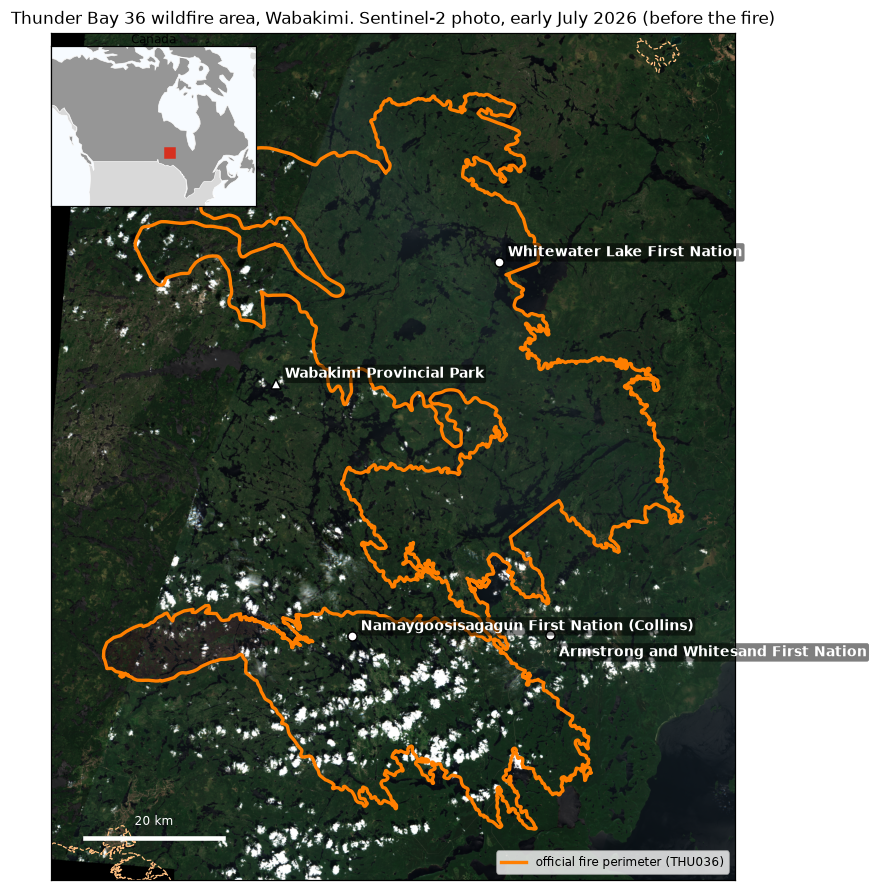

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 10))
ax.imshow(photo_rgb, extent=extent(GRID))
draw_outline(ax, other_fires, GRID, color="#ffbf80", lw=0.8)
ax.lines[-1].set_linestyle("--") if ax.lines else None
for line in ax.lines:
    line.set_linestyle("--")
draw_outline(ax, perimeter, GRID, lw=2.2, label="official fire perimeter (THU036)")
for _, t in places.to_crs(UTM).iterrows():
    marker = "o" if t["kind"] == "community" else "^"
    ax.plot(t.geometry.x, t.geometry.y, marker, ms=6, mfc="white", mec="black")
    below = t["name"].startswith("Armstrong")          # keep the two southern labels apart
    ax.annotate(t["name"], (t.geometry.x, t.geometry.y), xytext=(6, -14 if below else 4), textcoords="offset points",
                color="white", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.5, lw=0))
ax.set_xlim(extent(GRID)[:2])
ax.set_ylim(extent(GRID)[2:])
clean_axes(ax, "Thunder Bay 36 wildfire area, Wabakimi. Sentinel-2 photo, early July 2026 (before the fire)")
ax.legend(loc="lower right", fontsize=8)
scale_bar(ax, km=20)

inset = ax.inset_axes([0.0, 0.78, 0.30, 0.22])
world.plot(ax=inset, color="#d9d9d9", edgecolor="white", lw=0.4)
world[world["NAME"] == "Canada"].plot(ax=inset, color="#969696", edgecolor="white", lw=0.4)
inset.plot(np.mean(BBOX[::2]), np.mean(BBOX[1::2]), "s", color="#d7301f", ms=6)
inset.set_xlim(-141, -52)
inset.set_ylim(40, 72)
for f in (inset.set_xticks, inset.set_yticks):
    f([])
inset.set_xlabel("")
inset.set_ylabel("")
inset.set_facecolor("#f7fbff")
inset.set_title("Canada", fontsize=8, pad=2)
plt.show()

## 2. The NISAR data and how we fetch it

| | |
|---|---|
| Satellite | NISAR (NASA and ISRO), launched July 2025 |
| Radar | **L-band**, 24 cm wavelength: passes through smoke and reaches into the canopy |
| Product | **GCOV level 2** (calibrated backscatter on a map grid), collection `NISAR_L2_GCOV_PROVISIONAL_V1` |
| Pixel | delivered at 10 m; we average 4 x 4 pixels to 40 m |
| Channels used | **HV** (main) and HH (for comparison) |
| Archive | NASA Earthdata (Alaska Satellite Facility), free account, password in `~/.netrc` |

**Why HV for a forest fire.** The radar sends a horizontal wave (H) and listens in two ways:
- **HV** (horizontal sent, vertical received) only comes back when the wave bounces many times inside a **volume** of needles, leaves and branches. It measures the **canopy**. When the canopy burns, there is less to bounce in, so **HV drops**.
- **HH** reacts more to the ground, trunks and moisture; it is shown for comparison only.

The search below asks NASA's catalogue (CMR) for every NISAR file over the box from June to mid-November 2026.

In [7]:
files = nisar_files(BBOX, "2026-06-01", "2026-11-14")
print(f"{len(files)} NISAR files touch the box, per pass (track and frame):")
print(files.groupby(["track", "frame"]).date.nunique().rename("dates").to_string())

73 NISAR files touch the box, per pass (track and frame):
track  frame
018A   027       9
       028       9
041D   063       9
047A   027      10
113D   063       9
119A   027       9
142D   062       9
       063       9


Several passes cover the fire. We keep **track 041D, frame 063** (descending orbit): it covers the whole box on every date, with the same acquisition mode on all 9 dates (June 17 to October 15), and it passed over the area on **July 11, one day before the fire got its name**. NISAR has no data between July 27 and August 10, 2026.

| Role | Date | Why |
|---|---|---|
| **Before** | **2026-07-11** | last pass before the fire (July 12) |
| **During** | **2026-07-23** | first pass after: the fire had passed 315,000 ha and was still out of control |
| **After** | **2026-09-21** | the fire no longer growing; between the cloud-free Sentinel-2 images of September 20 and 22 used for the optical check, and the pass where the canopy loss stands out best (see section 8) |

Lightning had already started a few smaller fires in the area from July 6, so the July 11 image is not perfectly "before" everywhere; section 8 shows how much.

In [8]:
use = files[(files.track == "041D") & (files.frame == "063") & (files.channels == "DHDH") & files.full_frame]
use = use.drop_duplicates("date").reset_index(drop=True)
DATES = list(use.date)
BEFORE, EVENT_PASS, AFTER = "2026-07-11", "2026-07-23", "2026-09-21"
use[["date", "mode", "channels", "file"]]

,date,mode,channels,file
0,2026-06-17,4005,DHDH,NISAR_L2_PR_GCOV_023_041_D_063_4005_DHDH_A_202...
1,2026-06-29,4005,DHDH,NISAR_L2_PR_GCOV_024_041_D_063_4005_DHDH_A_202...
2,2026-07-11,4005,DHDH,NISAR_L2_PR_GCOV_025_041_D_063_4005_DHDH_A_202...
3,2026-07-23,4005,DHDH,NISAR_L2_PR_GCOV_026_041_D_063_4005_DHDH_A_202...
4,2026-08-16,4005,DHDH,NISAR_L2_PR_GCOV_028_041_D_063_4005_DHDH_A_202...
5,2026-09-09,4005,DHDH,NISAR_L2_PR_GCOV_030_041_D_063_4005_DHDH_A_202...
6,2026-09-21,4005,DHDH,NISAR_L2_PR_GCOV_031_041_D_063_4005_DHDH_A_202...
7,2026-10-03,4005,DHDH,NISAR_L2_PR_GCOV_032_041_D_063_4005_DHDH_A_202...
8,2026-10-15,4005,DHDH,NISAR_L2_PR_GCOV_033_041_D_063_4005_DHDH_A_202...


### Reading each date

For each date: open the file over HTTPS, read the box in strips of rows, average each 4 x 4 block of 10 m pixels into one 40 m pixel (as echo power, before converting), put it on our grid and convert to **decibels**:

$$\text{dB} = 10 \cdot \log_{10}(\text{echo power})$$

The box is about 95 km by 120 km, so the first run streams about 3 minutes per date from NASA; the result is cached in `data/case5/cache/`.

In [9]:
earthaccess.login(strategy="netrc")
scenes = [load_date(KEY, r, GRID) for _, r in use.iterrows()]
RAW = xr.concat(scenes, dim=pd.Index(DATES, name="date")).rio.write_crs(UTM)   # HH and HV (dB) as delivered
del scenes
pd.DataFrame({"date": DATES,
              "valid pixels in the box %": [round(float(np.isfinite(RAW.HV.sel(date=d)).mean() * 100), 1) for d in DATES],
              "perimeter covered %": [round(float(np.isfinite(RAW.HV.sel(date=d).values[INSIDE]).mean() * 100), 1) for d in DATES]})

,date,valid pixels in the box %,perimeter covered %
0,2026-06-17,100.0,100.0
1,2026-06-29,100.0,100.0
2,2026-07-11,100.0,100.0
3,2026-07-23,100.0,100.0
4,2026-08-16,100.0,100.0
5,2026-09-09,100.0,100.0
6,2026-09-21,100.0,100.0
7,2026-10-03,100.0,100.0
8,2026-10-15,100.0,100.0


## 3. The raw radar: before and after

HV on the same grey scale on both dates (-25 dB black, -5 dB white), with the official perimeter in orange. Forest is bright in HV (a lot of canopy to bounce in); the hundreds of lakes of Wabakimi are black. Inside the perimeter, large areas are clearly **darker** after the fire.

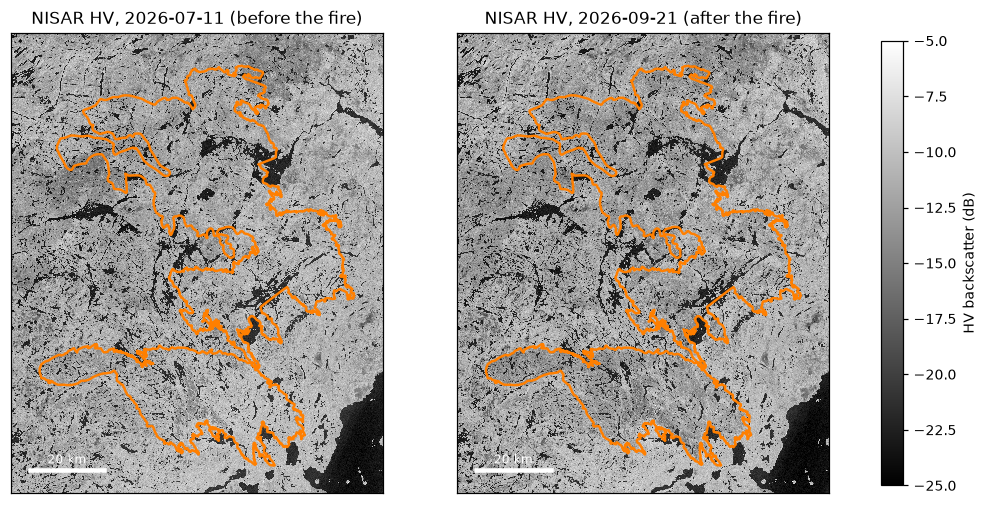

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7.5))
for ax, d, label in zip(axes, (BEFORE, AFTER), ("before the fire", "after the fire")):
    im = show_radar(ax, GRID, RAW.HV.sel(date=d), f"NISAR HV, {d} ({label})")
    draw_outline(ax, perimeter, GRID)
    scale_bar(ax, km=20)
fig.colorbar(im, ax=axes, shrink=0.7, label="HV backscatter (dB)")
plt.show()

### Speckle, and how we clean it

As in cases 2 and 3, each radar pixel is grainy (**speckle**): a pixel can jump by several dB with no change on the ground. The 4 x 4 averaging to 40 m already reduces it; we then replace each pixel by the **median of the 5 x 5 pixels** around it (200 m by 200 m). All rules use this cleaned image; the raw one is kept to compare in the app.

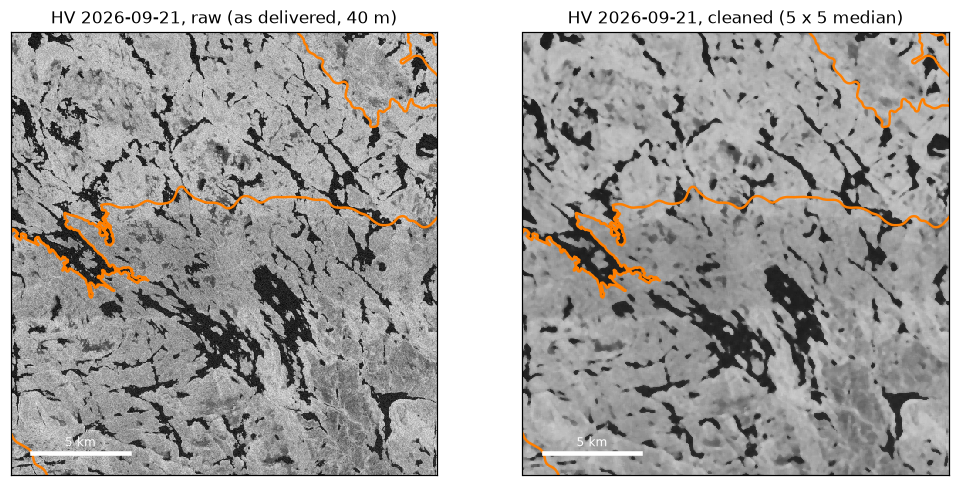

In [11]:
CLEAN = xr.Dataset({b: xr.concat([despeckle(RAW[b].sel(date=d)) for d in DATES], dim=pd.Index(DATES, name="date"))
                    for b in ("HH", "HV")}).rio.write_crs(UTM)

ZOOM = (-89.62, 50.20, -89.32, 50.40)   # about 21 km x 22 km around Collins Lake (Namaygoosisagagun), used for close-ups
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, img, label in zip(axes, (RAW, CLEAN), ("raw (as delivered, 40 m)", "cleaned (5 x 5 median)")):
    show_radar(ax, GRID, img.HV.sel(date=AFTER), f"HV {AFTER}, {label}")
    draw_outline(ax, perimeter, GRID)
    zoom_to(ax, GRID, *ZOOM)
    scale_bar(ax, km=5)
plt.show()

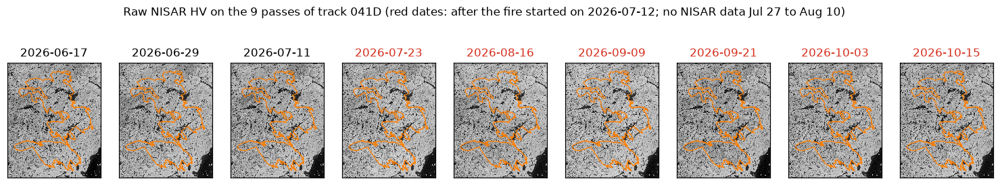

In [12]:
fig, axes = plt.subplots(1, len(DATES), figsize=(1.9 * len(DATES), 2.8))
for ax, d in zip(axes, DATES):
    show_radar(ax, GRID, RAW.HV.sel(date=d).values[::3, ::3], d)
    draw_outline(ax, perimeter, GRID, lw=0.8)
    ax.title.set_color("#d7301f" if d > FIRE_START else "black")
fig.suptitle(f"Raw NISAR HV on the {len(DATES)} passes of track 041D (red dates: after the fire started on {FIRE_START}; no NISAR data Jul 27 to Aug 10)", y=1.04)
plt.show()

## 4. What a fire does to the radar echo

A boreal crown fire removes the needles and small branches but leaves many burned trunks standing on blackened, often wet ground. The radar sees two things:

| Situation | HV (canopy) | HH | Colour | When we see it best |
|---|---|---|---|---|
| **Canopy burned** (moderate to high severity) | **drops**: fewer needles and branches for the wave to bounce in | | yellow, red | best on September 21; hidden on some passes, most likely when the burned ground is wet |
| **Canopy gone, trunks and ground exposed** | | **brighter**: the pulse bounces from the ground to the standing trunks and straight back (**double bounce**, the same effect as the flooded villages of case 2) | violet | right after the fire (July 23) |
| Light ground fire (canopy still there) | little change | little change | | not visible to the radar |
| **Rain, wet ground, season or a calibration shift** | rises or falls **everywhere at once** | same | | removed by comparing with the unburned forest around the fire (section 5) |
| **Logging, clear-cut, other fires** | drops too | changes | | checked with the date and the fire detections (section 8), the official perimeter (section 7), and other 2026 fires kept out of the reference |

The graph below follows the median HV and HH on every date in two zones: **inside the official perimeter**, and in a **ring of unburned forest 1 to 6 km outside it** (other 2026 fires removed from the ring). Both zones move up and down together with the weather and the season; what matters is the **gap between them**. After the fire, the HH gap opens upwards at once (double bounce), while the HV gap opens downwards, most clearly on September 21. On some passes it nearly closes again, most likely because wet burned ground also returns HV and hides part of the canopy loss.

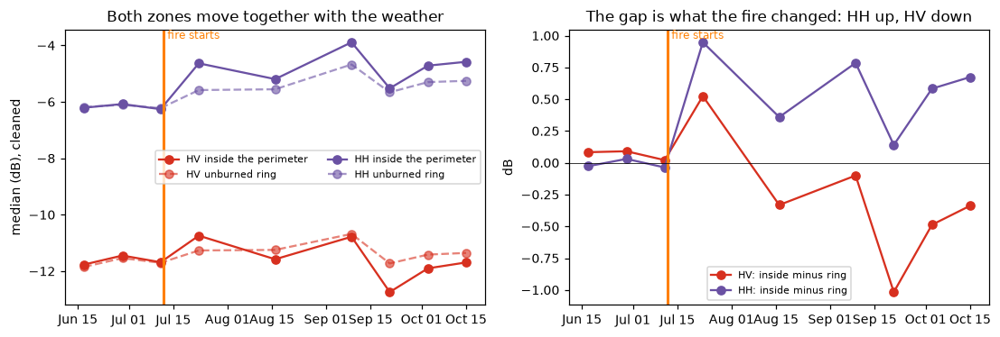

,HV inside,HV ring,HH inside,HH ring
2026-06-17,-11.76,-11.85,-6.21,-6.18
2026-06-29,-11.45,-11.54,-6.08,-6.11
2026-07-11,-11.68,-11.70,-6.26,-6.22
2026-07-23,-10.74,-11.27,-4.63,-5.58
2026-08-16,-11.58,-11.25,-5.19,-5.55
2026-09-09,-10.78,-10.68,-3.89,-4.67
2026-09-21,-12.74,-11.72,-5.52,-5.66
2026-10-03,-11.90,-11.41,-4.72,-5.30
2026-10-15,-11.69,-11.35,-4.58,-5.25


In [13]:
dist = ndimage.distance_transform_edt(~INSIDE) * PIXEL_M
RING = (dist > 1000) & (dist < 6000) & ~OTHER_FIRES   # unburned forest around the fire, our reference zone

zones = pd.DataFrame({f"{b} {name}": [float(np.nanmedian(CLEAN[b].sel(date=d).values[mask])) for d in DATES]
                      for b in ("HV", "HH") for name, mask in (("inside", INSIDE), ("ring", RING))},
                     index=pd.to_datetime(DATES))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for b, color in (("HV", "#d7301f"), ("HH", "#6a51a3")):
    axes[0].plot(zones.index, zones[f"{b} inside"], "o-", color=color, label=f"{b} inside the perimeter")
    axes[0].plot(zones.index, zones[f"{b} ring"], "o--", color=color, alpha=0.6, label=f"{b} unburned ring")
    axes[1].plot(zones.index, zones[f"{b} inside"] - zones[f"{b} ring"], "o-", color=color, label=f"{b}: inside minus ring")
for ax in axes:
    ax.axvline(pd.Timestamp(FIRE_START), color="#ff7f00", lw=2)
    ax.text(pd.Timestamp(FIRE_START), ax.get_ylim()[1], " fire starts", color="#ff7f00", va="top", fontsize=8)
    ax.xaxis.set_major_formatter(__import__("matplotlib.dates").dates.DateFormatter("%b %d"))
axes[0].set_ylabel("median (dB), cleaned")
axes[0].set_title("Both zones move together with the weather")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("dB")
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_title("The gap is what the fire changed: HH up, HV down")
axes[1].legend(fontsize=7)
plt.show()
zones.round(2)

## 5. Choosing the thresholds from the data

### 5a. Relative change

For every pixel we compute the change between two dates, in dB, and remove the **common change** of the scene, the median change of the unburned ring. What is left is the change **specific to that pixel**:

$$\Delta_{relative} = \big(\text{dB}(\text{after}) - \text{dB}(\text{before})\big) - \text{median of the same change in the unburned ring}$$

We use it twice, both times against July 11:
- **HV on September 21** for the canopy loss;
- **HH on July 23** for the double bounce right after the fire.

A difference in dB is a ratio: **-1 dB means the echo fell by about 20 %**, +1 dB means it rose by about 26 %.

Common change of the unburned ring: HV 2026-07-11 -> 2026-09-21: -0.03 dB, HH 2026-07-11 -> 2026-07-23: +0.58 dB (removed from every pixel)


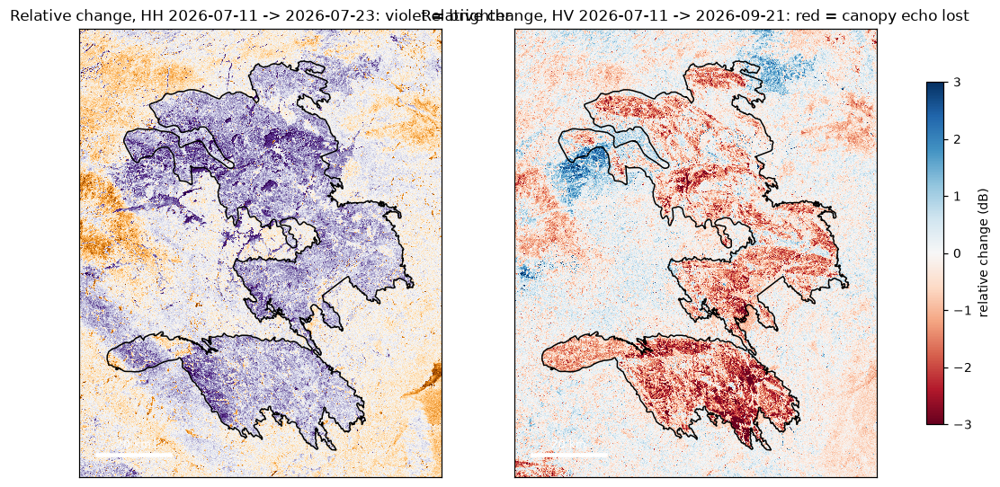

In [14]:
def relative_change(clean, band, before, after, reference):
    """Change in dB between two dates, minus the median change of the reference (unburned) zone."""
    b, a = clean[band].sel(date=before).values, clean[band].sel(date=after).values
    valid = np.isfinite(a) & np.isfinite(b)
    change = a - b
    common = float(np.nanmedian(change[reference & valid]))
    return change - common, common, valid


REL, COMMON, VALID = relative_change(CLEAN, "HV", BEFORE, AFTER, RING)          # canopy loss
REL_HH, COMMON_HH, VALID_HH = relative_change(CLEAN, "HH", BEFORE, EVENT_PASS, RING)   # double bounce
print(f"Common change of the unburned ring: HV {BEFORE} -> {AFTER}: {COMMON:+.2f} dB, HH {BEFORE} -> {EVENT_PASS}: {COMMON_HH:+.2f} dB "
      "(removed from every pixel)")

fig, axes = plt.subplots(1, 2, figsize=(13, 7.5))
for ax, rel, valid, title in ((axes[0], REL_HH, VALID_HH, f"HH {BEFORE} -> {EVENT_PASS}: violet = brighter"),
                              (axes[1], REL, VALID, f"HV {BEFORE} -> {AFTER}: red = canopy echo lost")):
    cmap = "PuOr" if ax is axes[0] else "RdBu"
    im = ax.imshow(np.where(valid, rel, np.nan), cmap=cmap, vmin=-3, vmax=3, extent=extent(GRID), interpolation="nearest")
    draw_outline(ax, perimeter, GRID, color="black", lw=1.0)
    scale_bar(ax, km=20)
    clean_axes(ax, "Relative change, " + title)
fig.colorbar(im, ax=axes, shrink=0.6, label="relative change (dB)")
plt.show()

### 5b. How much does the echo move when nothing burns?

In the unburned ring the relative change is never exactly 0 (leftover speckle, moisture, small forest changes). We measure that **normal movement** (its spread, the standard deviation) and set the thresholds at **2 and 3 times** that spread, rounded to a whole dB, exactly as in case 3:
- **canopy loss** (HV): a drop of at least 2 times the normal movement; **severe**: 3 times;
- **brighter** (HH): a rise of at least 2 times the normal movement.

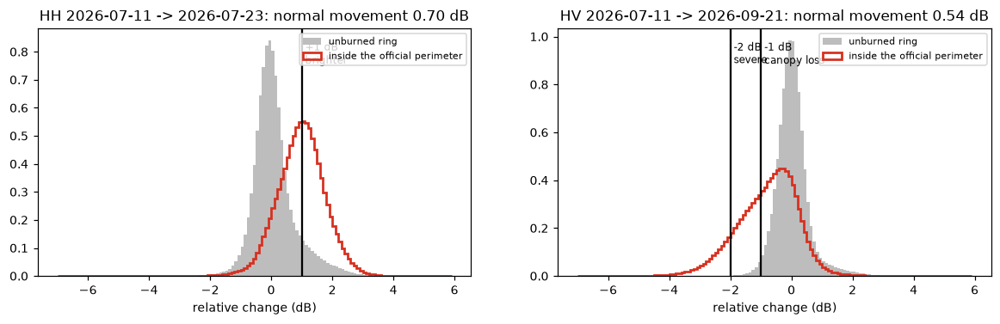

,rule,unburned ring pixels past it %,pixels inside the perimeter past it %
0,"HH brighter, +1 dB",9.9,49.6
1,"HV canopy loss, -1 dB",1.7,37.9
2,"HV severe, -2 dB",0.1,11.7


In [15]:
NOISE = float(np.std(REL[RING & VALID]))
NOISE_HH = float(np.std(REL_HH[RING & VALID_HH]))
T_LOSS = max(1.0, float(np.round(2 * NOISE)))
T_SEVERE = max(T_LOSS + 1, float(np.round(3 * NOISE)))
T_BRIGHT = max(1.0, float(np.round(2 * NOISE_HH)))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
bins = np.arange(-7, 6, 0.1)
for ax, rel, valid, noise, lines, title in (
        (axes[0], REL_HH, VALID_HH, NOISE_HH, ((T_BRIGHT, "brighter"),), f"HH {BEFORE} -> {EVENT_PASS}"),
        (axes[1], REL, VALID, NOISE, ((-T_LOSS, "canopy loss"), (-T_SEVERE, "severe")), f"HV {BEFORE} -> {AFTER}")):
    ax.hist(rel[RING & valid], bins=bins, density=True, color="#bdbdbd", label="unburned ring")
    ax.hist(rel[INSIDE & valid], bins=bins, density=True, histtype="step", lw=1.8, color="#d7301f", label="inside the official perimeter")
    for t, name in lines:
        ax.axvline(t, color="black", lw=1.5)
        ax.text(t, ax.get_ylim()[1] * 0.95, f" {t:+.0f} dB\n {name}", fontsize=8, va="top")
    ax.set_xlabel("relative change (dB)")
    ax.set_title(f"{title}: normal movement {noise:.2f} dB")
    ax.legend(loc="upper right", fontsize=7)
plt.show()

pd.DataFrame({"rule": [f"HH brighter, +{T_BRIGHT:.0f} dB", f"HV canopy loss, -{T_LOSS:.0f} dB", f"HV severe, -{T_SEVERE:.0f} dB"],
              "unburned ring pixels past it %": [round(100 * (REL_HH[RING & VALID_HH] >= T_BRIGHT).mean(), 1),
                                                  round(100 * (REL[RING & VALID] <= -T_LOSS).mean(), 1),
                                                  round(100 * (REL[RING & VALID] <= -T_SEVERE).mean(), 1)],
              "pixels inside the perimeter past it %": [round(100 * (REL_HH[INSIDE & VALID_HH] >= T_BRIGHT).mean(), 1),
                                                         round(100 * (REL[INSIDE & VALID] <= -T_LOSS).mean(), 1),
                                                         round(100 * (REL[INSIDE & VALID] <= -T_SEVERE).mean(), 1)]})

## 6. The rules and their maps

Per pixel, with the cleaned images and the thresholds above:

| Rule | Test | Meaning | Colour |
|---|---|---|---|
| vegetated before | HV(July 11) > -18 dB | there was a forest to burn (excludes lakes, rock, bare ground) | |
| **brighter** | relative ΔHH (July 23) ≥ +T_bright | canopy gone, the pulse bounces between the ground and the burned trunks | violet `#6a51a3` |
| **canopy loss** | relative ΔHV (September 21) ≤ -T_loss | the canopy echo fell clearly more than normal | yellow `#fec44f` |
| **severe canopy loss** | relative ΔHV (September 21) ≤ -T_severe | the canopy echo fell strongly | red `#d7301f` |

Single pixels can fire on speckle alone, so we keep a pixel only if it belongs to a **patch of at least 9 pixels** (1.4 ha at 40 m).

In [16]:
BURN_COLORS = {1: "#fec44f", 2: "#d7301f"}
BURN_LABELS = {0: "no canopy change", 1: "canopy loss", 2: "severe canopy loss"}
BRIGHT_COLOR = "#6a51a3"
BRIGHT_LABEL = "brighter: burned trunks on bare ground (double bounce)"
VEG_MIN_DB = -18.0      # HV before above this: there was vegetation
MIN_PATCH_PX = 9        # 3 x 3 pixels = 1.44 ha at 40 m
NODATA = 255


def keep_patches(mask):
    """Keep pixels of `mask` that belong to connected patches of at least MIN_PATCH_PX pixels."""
    labels, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    size = np.bincount(labels.ravel())
    ok = size >= MIN_PATCH_PX
    ok[0] = False
    return ok[labels]


def vegetated(clean, before):
    return clean["HV"].sel(date=before).values > VEG_MIN_DB


def burn_codes(clean, before, after, rel, valid):
    """Canopy loss map (HV): 0 no change, 1 canopy loss, 2 severe canopy loss, 255 no data."""
    loss = keep_patches(valid & vegetated(clean, before) & (rel <= -T_LOSS))
    severe = loss & (rel <= -T_SEVERE)
    codes = np.where(severe, 2, np.where(loss, 1, 0)).astype("uint8")
    codes[~valid] = NODATA
    return codes


def bright_codes(clean, before, rel, valid):
    """Double-bounce map (HH): 0 no change, 1 brighter, 255 no data."""
    codes = keep_patches(valid & vegetated(clean, before) & (rel >= T_BRIGHT)).astype("uint8")
    codes[~valid] = NODATA
    return codes


def km2(mask):
    return round(float(mask.sum()) * PIXEL_M**2 / 1e6, 1)


CODES = burn_codes(CLEAN, BEFORE, AFTER, REL, VALID)
BRIGHT = bright_codes(CLEAN, BEFORE, REL_HH, VALID_HH)
areas = pd.DataFrame({zone: {f"brighter in HH on {EVENT_PASS}": km2((BRIGHT == 1) & m),
                             **{f"{BURN_LABELS[k]} in HV on {AFTER}": km2((CODES == k) & m) for k in (1, 2)}}
                      for zone, m in (("whole box", np.ones_like(INSIDE)), ("inside official perimeter", INSIDE),
                                      ("outside perimeter", ~INSIDE))})
areas.index.name = "km²"
areas

,whole box,inside official perimeter,outside perimeter
km²,,,
brighter in HH on 2026-07-23,1857.1,1514.0,343.1
canopy loss in HV on 2026-09-21,1055.9,865.7,190.2
severe canopy loss in HV on 2026-09-21,424.6,408.2,16.5


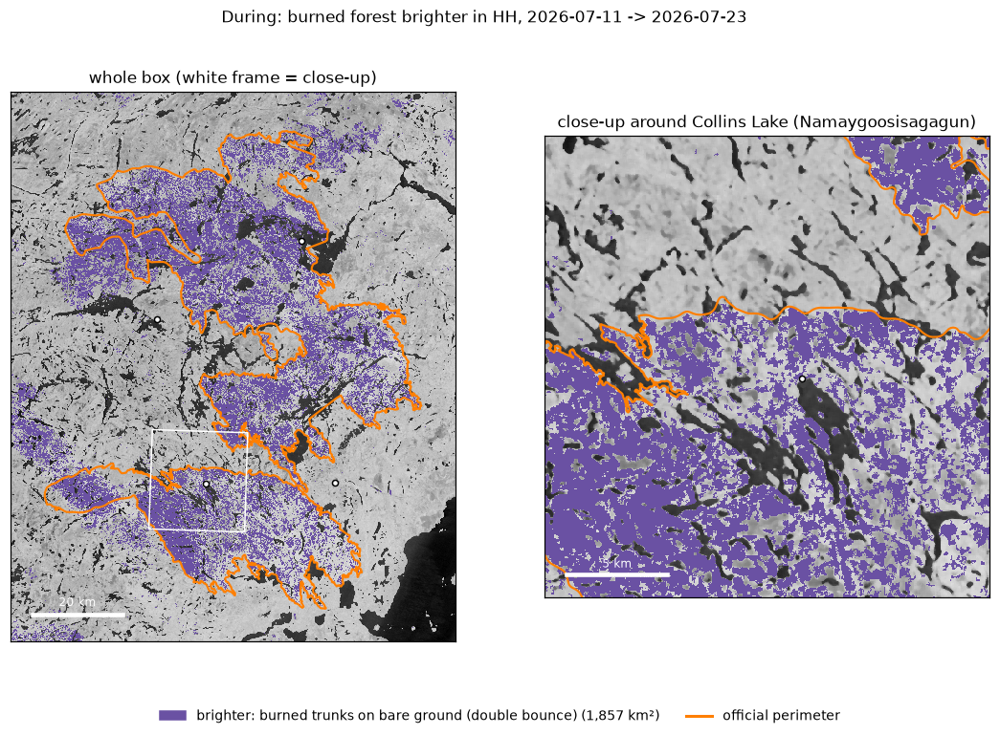

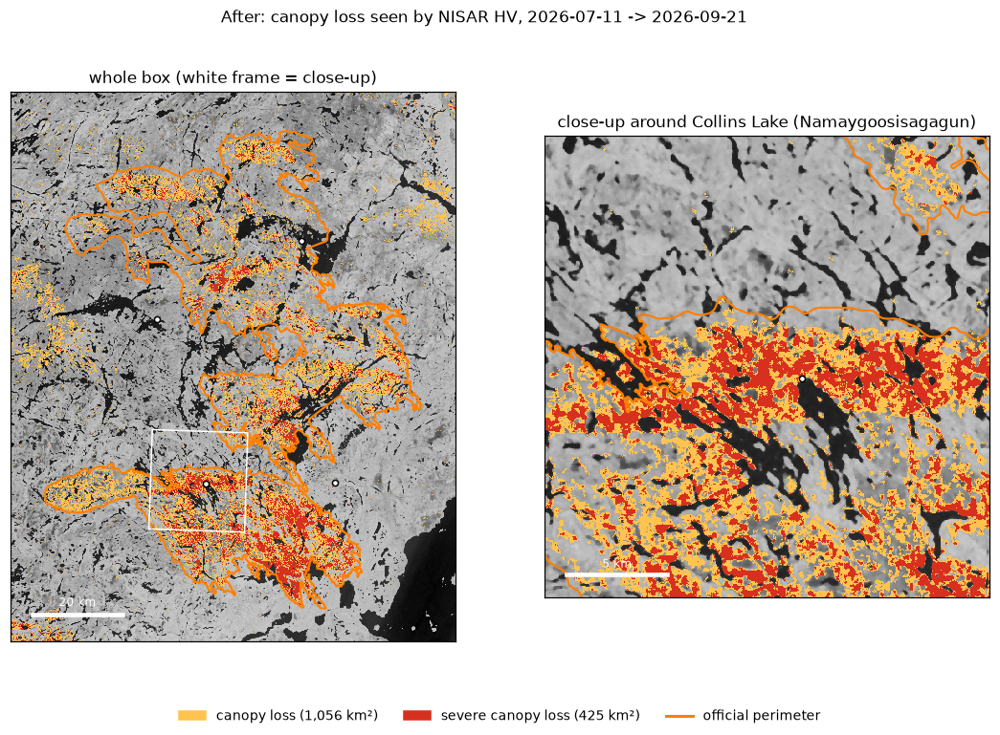

In [17]:
def change_figure(grid, background, codes, colors, labels, outline, zoom, title, vrange=(-25, -5)):
    """Whole box (left) and close-up (right): classes over a cleaned radar image."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 7))
    for ax, z in zip(axes, (None, zoom)):
        show_radar(ax, grid, background, "", *vrange)
        show_classes(ax, grid, codes, colors)
        draw_outline(ax, outline, grid, lw=1.4)
        for _, t in places.to_crs(grid.rio.crs).iterrows():
            ax.plot(t.geometry.x, t.geometry.y, "o", ms=4, mfc="white", mec="black")
        if z:
            zoom_to(ax, grid, *z)
            scale_bar(ax, km=5)
        else:
            ax.plot(*box_xy(grid, *zoom), color="white", lw=1)
            scale_bar(ax, km=20)
    axes[0].set_title("whole box (white frame = close-up)")
    axes[1].set_title("close-up around Collins Lake (Namaygoosisagagun)")
    handles = [Patch(color=colors[k], label=f"{labels[k]} ({km2(codes == k):,.0f} km²)") for k in colors]
    handles.append(__import__("matplotlib.lines").lines.Line2D([], [], color="#ff7f00", lw=2, label="official perimeter"))
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(title, y=0.98)
    plt.show()
    plt.close(fig)


change_figure(GRID, CLEAN.HH.sel(date=EVENT_PASS), BRIGHT, {1: BRIGHT_COLOR}, {1: BRIGHT_LABEL}, perimeter, ZOOM,
              f"During: burned forest brighter in HH, {BEFORE} -> {EVENT_PASS}", vrange=(-20, 0))
change_figure(GRID, CLEAN.HV.sel(date=AFTER), CODES, BURN_COLORS, BURN_LABELS, perimeter, ZOOM,
              f"After: canopy loss seen by NISAR HV, {BEFORE} -> {AFTER}")

## 7. Checking the result against two independent references

### 7a. The official fire perimeter

The Ontario Ministry of Natural Resources perimeter (THU036) is the outer line of the fire, mapped from aircraft and satellites. Two questions:
- **Where does the radar find change?** If it is a fire signal, it should be almost all **inside** the perimeter.
- **How much of the perimeter does it flag?** Not all of it: the perimeter includes lakes (many in Wabakimi), unburned islands and lightly burned ground.

In [18]:
burned = (CODES == 1) | (CODES == 2)
bright = BRIGHT == 1
either = burned | bright
valid_inside = INSIDE & VALID
vegetated_inside = valid_inside & vegetated(CLEAN, BEFORE)


def perimeter_check(mask):
    return {"total (km²)": km2(mask), "inside the official perimeter (%)": round(100 * (mask & INSIDE).sum() / mask.sum(), 1),
            "share of the vegetated perimeter flagged (%)": round(100 * (mask & vegetated_inside).sum() / vegetated_inside.sum(), 1),
            "outside the perimeter (km²)": km2(mask & ~INSIDE), "  of which in other 2026 fires (km²)": km2(mask & ~INSIDE & OTHER_FIRES)}


print(f"Official perimeter seen by the radar: {km2(valid_inside):,.0f} km², of which vegetated before the fire (not lakes): {km2(vegetated_inside):,.0f} km²")
pd.DataFrame({f"brighter HH ({EVENT_PASS})": perimeter_check(bright), f"canopy loss HV ({AFTER})": perimeter_check(burned),
              "either signal": perimeter_check(either)})

Official perimeter seen by the radar: 3,512 km², of which vegetated before the fire (not lakes): 3,124 km²


,brighter HH (2026-07-23),canopy loss HV (2026-09-21),either signal
total (km²),1857.1,1480.6,2712.0
inside the official perimeter (%),81.5,86.0,80.1
share of the vegetated perimeter flagged (%),48.5,40.8,69.5
outside the perimeter (km²),343.1,206.7,540.6
of which in other 2026 fires (km²),23.8,29.7,45.2


### 7b. Burn severity from Sentinel-2 (optical)

Optical satellites measure burn severity with the **Normalized Burn Ratio**. Healthy vegetation reflects a lot of near infrared (NIR) and little short-wave infrared (SWIR); burned ground does the opposite:

$$NBR = \frac{NIR - SWIR}{NIR + SWIR} \qquad dNBR = NBR(\text{before}) - NBR(\text{after})$$

One Sentinel-2 pass does not cover this large box, so each image combines several cloud-free days: **July 7 and 4 (and June 2)** before, **September 22, 20 and 10** after. The dNBR classes are the standard ones of the US Geological Survey (Key and Benson): below 0.1 unburned, 0.1 to 0.27 low, 0.27 to 0.44 moderate-low, 0.44 to 0.66 moderate-high, above 0.66 high severity. Lakes are left out (NBR is meaningless on water).

This is a completely independent measurement (sunlight reflected by the ground, not radar), so it is a fair test of the radar maps.

In [19]:
def sentinel2_band(key, grid, bbox, days, asset):
    """One Sentinel-2 band as surface reflectance (0 to 1) on the grid (read at 40 m), combined from several clear days, cached."""
    path = CACHE / f"{key}_sentinel2_{'_'.join(days)}_{asset}.tif"
    if not path.exists():
        out = None
        for item in clear_tiles(bbox, days):
            tile = rioxarray.open_rasterio(item["assets"][asset]["href"], overview_level=0).squeeze(drop=True)   # 40 m version
            try:
                tile = tile.rio.clip_box(*bbox, crs="EPSG:4326")
            except Exception:
                continue
            part = tile.rio.reproject_match(grid, nodata=0).values.astype("float32")
            info = item["assets"][asset]["raster:bands"][0]
            # digital number -> reflectance; the catalogue says when its offset is already applied to the numbers
            offset = 0.0 if item["properties"].get("earthsearch:boa_offset_applied") else info.get("offset", 0.0)
            part = np.where(part > 0, part * info.get("scale", 1e-4) + offset, np.nan)
            out = part if out is None else np.where(np.isfinite(out), out, part)   # first clear pixel wins
        grid.copy(data=out.astype("float32")).rio.to_raster(path, compress="deflate")
    return rioxarray.open_rasterio(path).squeeze(drop=True).values


PHOTO_AFTER = ["2026-09-22", "2026-09-20", "2026-09-10"]   # clear days after the fire, first choice first
nbr = {}
for key, days in (("before", PHOTO_BEFORE), ("after", PHOTO_AFTER)):
    nir, swir = sentinel2_band(KEY, GRID, BBOX, days, "nir08"), sentinel2_band(KEY, GRID, BBOX, days, "swir22")
    with np.errstate(divide="ignore", invalid="ignore"):
        nbr[key] = (nir - swir) / (nir + swir)
DNBR = np.where(vegetated(CLEAN, BEFORE), nbr["before"] - nbr["after"], np.nan)
print(f"Optical burn severity available on {100 * np.isfinite(DNBR).mean():.1f} % of the box (lakes excluded)")

SEVERITY = [(-np.inf, 0.10, "unburned"), (0.10, 0.27, "low"), (0.27, 0.44, "moderate-low"),
            (0.44, 0.66, "moderate-high"), (0.66, np.inf, "high")]
SEVERITY_COLORS = ["#f0f0f0", "#ffffb2", "#fecc5c", "#fd8d3c", "#bd0026"]
severity = np.full(DNBR.shape, -1)
for i, (lo, hi, _) in enumerate(SEVERITY):
    severity[(DNBR >= lo) & (DNBR < hi)] = i

rows = []
for i, (lo, hi, name) in enumerate(SEVERITY):
    m = (severity == i) & VALID & VALID_HH
    rows.append({"optical burn severity (dNBR)": name, "area in the box (km²)": km2(m),
                 "inside the perimeter (km²)": km2(m & INSIDE),
                 f"brighter HH {EVENT_PASS[5:]} %": round(100 * bright[m].mean(), 1),
                 f"canopy loss HV {AFTER[5:]} %": round(100 * burned[m].mean(), 1),
                 "severe %": round(100 * (CODES[m] == 2).mean(), 1),
                 "either signal %": round(100 * either[m].mean(), 1)})
pd.DataFrame(rows)

Optical burn severity available on 85.0 % of the box (lakes excluded)


,optical burn severity (dNBR),area in the box (km²),inside the perimeter (km²),brighter HH 07-23 %,canopy loss HV 09-21 %,severe %,either signal %
0,unburned,7497.2,500.5,4.8,3.1,0.1,7.5
1,low,441.0,208.8,22.6,7.0,0.8,28.0
2,moderate-low,264.1,237.7,41.2,15.4,3.2,51.5
3,moderate-high,439.6,421.9,51.2,25.3,7.7,66.9
4,high,1776.3,1754.8,58.9,58.7,20.5,87.9


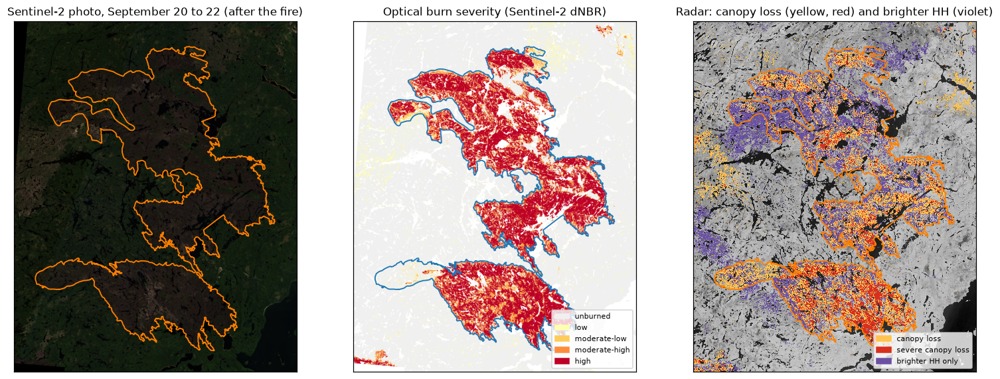

In [20]:
photo_after = sentinel2_photo(KEY, GRID, BBOX, PHOTO_AFTER)
fig, axes = plt.subplots(1, 3, figsize=(17, 7.5))
axes[0].imshow(np.moveaxis(photo_after.values, 0, -1), extent=extent(GRID))
clean_axes(axes[0], "Sentinel-2 photo, September 20 to 22 (after the fire)")
sev_rgba = np.zeros(DNBR.shape + (4,), "uint8")
for i, c in enumerate(SEVERITY_COLORS):
    sev_rgba[severity == i] = [int(c[j:j + 2], 16) for j in (1, 3, 5)] + [255]
axes[1].imshow(sev_rgba, extent=extent(GRID))
clean_axes(axes[1], "Optical burn severity (Sentinel-2 dNBR)")
show_radar(axes[2], GRID, CLEAN.HV.sel(date=AFTER), "Radar: canopy loss (yellow, red) and brighter HH (violet)")
show_classes(axes[2], GRID, np.where(burned, CODES, np.where(bright, 3, 0)), {**BURN_COLORS, 3: BRIGHT_COLOR})
for ax in axes:
    draw_outline(ax, perimeter, GRID, color="#1f78b4" if ax is axes[1] else "#ff7f00", lw=1.2)
    ax.set_xlim(extent(GRID)[:2])
    ax.set_ylim(extent(GRID)[2:])
axes[1].legend(handles=[Patch(color=c, label=s[2]) for c, s in zip(SEVERITY_COLORS, SEVERITY)], loc="lower right", fontsize=7)
axes[2].legend(handles=[Patch(color=BURN_COLORS[k], label=BURN_LABELS[k]) for k in BURN_COLORS]
               + [Patch(color=BRIGHT_COLOR, label="brighter HH only")], loc="lower right", fontsize=7)
plt.show()

**How to read it.** Where the optical index sees a **high-severity** burn (canopy consumed), the radar flags most pixels, with one signal or the other; where it sees unburned forest, it flags very few. Low-severity burns (fire on the ground, canopy still standing) are mostly not flagged: the canopy the radar measures is still there.

## 8. Time series: is the change really the fire?

A clear-cut or a storm can also change the echo. A fire has a **date**: the change must appear **after July 12**, not before, and where satellites detected flames. We apply the same rules (same thresholds) to every date, always compared with July 11, and put them next to the daily count of **satellite fire detections** (hotspots from the Canadian Wildland Fire Information System) inside the perimeter.

49,102 satellite fire detections inside the perimeter in 2026; 48,239 (98%) between July 12 and July 22
Before the July 11 reference pass: 830 detections, mostly on June 3 around lon -89.83, lat 50.27 (an earlier fire at the western end of the southern lobe)


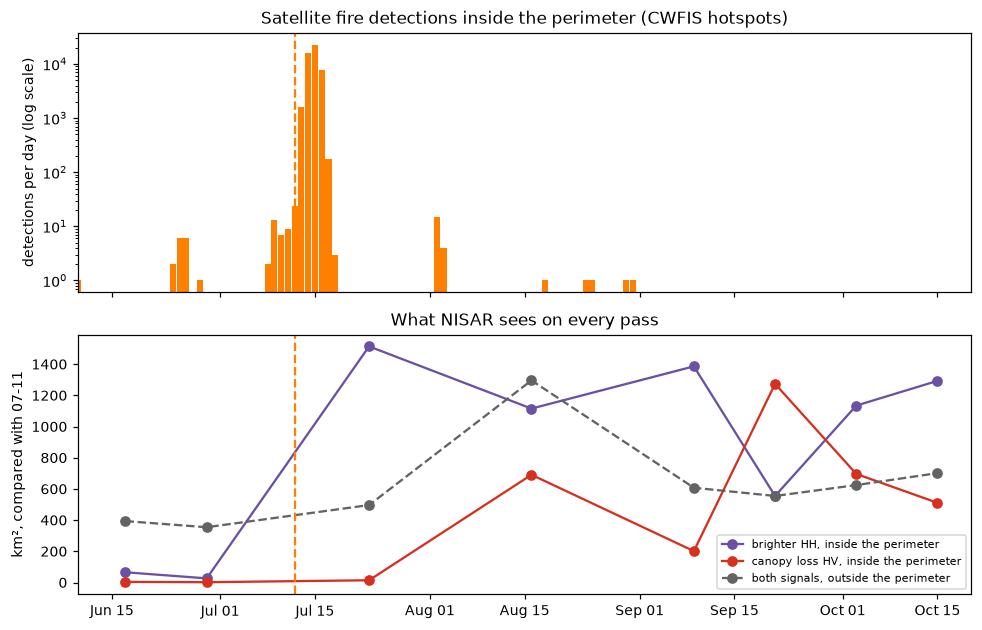

,canopy loss inside (km²),canopy loss outside (km²),brighter HH inside (km²),brighter HH outside (km²)
date,,,,
2026-06-17,3.9,161.3,65.6,232.5
2026-06-29,1.9,235.7,26.5,118.8
2026-07-23,14.4,153.5,1514.0,343.1
2026-08-16,690.9,215.2,1115.3,1080.7
2026-09-09,201.3,77.0,1386.1,530.6
2026-09-21,1273.9,206.7,554.9,348.2
2026-10-03,696.3,161.2,1134.5,463.6
2026-10-15,511.1,181.7,1293.0,519.7


In [21]:
series = []
for d in DATES:
    if d == BEFORE:
        continue
    rel, _, valid = relative_change(CLEAN, "HV", BEFORE, d, RING)
    loss = np.isin(burn_codes(CLEAN, BEFORE, d, rel, valid), (1, 2))
    rel_hh, _, valid_hh = relative_change(CLEAN, "HH", BEFORE, d, RING)
    bri = bright_codes(CLEAN, BEFORE, rel_hh, valid_hh) == 1
    series.append({"date": d, "canopy loss inside (km²)": km2(loss & INSIDE), "canopy loss outside (km²)": km2(loss & ~INSIDE),
                   "brighter HH inside (km²)": km2(bri & INSIDE), "brighter HH outside (km²)": km2(bri & ~INSIDE)})
series_df = pd.DataFrame(series).set_index("date")

hotspots = cwfis_hotspots(BBOX, KEY)
hotspots["day"] = hotspots["rep_date"].dt.floor("D")
hs = gpd.GeoDataFrame(hotspots, geometry=gpd.points_from_xy(hotspots.lon, hotspots.lat), crs=4326)
hs = hs[hs.within(perimeter.to_crs(4326).union_all())]
per_day = hs.groupby("day").size()
hs_window = int(per_day[(per_day.index >= "2026-07-12") & (per_day.index <= "2026-07-22")].sum())
hs_first10 = 100 * hs_window / len(hs)
early = hs[hs.day < BEFORE]
print(f"{len(hs):,} satellite fire detections inside the perimeter in 2026; {hs_window:,} ({hs_first10:.0f}%) between July 12 and July 22")
print(f"Before the July 11 reference pass: {len(early):,} detections, mostly on {early.day.dt.strftime('%B %-d').value_counts().index[0]} "
      f"around lon {early.lon.median():.2f}, lat {early.lat.median():.2f} (an earlier fire at the western end of the southern lobe)")

fig, axes = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True)
axes[0].bar(per_day.index, per_day.values, width=0.9, color="#ff7f00")
axes[0].set_yscale("log")
axes[0].set_ylabel("detections per day (log scale)")
axes[0].set_title("Satellite fire detections inside the perimeter (CWFIS hotspots)")
t = pd.to_datetime(series_df.index)
axes[1].plot(t, series_df["brighter HH inside (km²)"], "o-", color=BRIGHT_COLOR, label="brighter HH, inside the perimeter")
axes[1].plot(t, series_df["canopy loss inside (km²)"], "o-", color="#d7301f", label="canopy loss HV, inside the perimeter")
axes[1].plot(t, series_df["canopy loss outside (km²)"] + series_df["brighter HH outside (km²)"], "o--", color="#636363",
             label="both signals, outside the perimeter")
axes[1].set_ylabel(f"km², compared with {BEFORE[5:]}")
axes[1].set_title("What NISAR sees on every pass")
axes[1].legend(fontsize=7)
for ax in axes:
    ax.axvline(pd.Timestamp(FIRE_START), color="#ff7f00", lw=1.5, ls="--")
axes[1].set_xlim(pd.Timestamp("2026-06-10"), pd.Timestamp("2026-10-20"))
axes[1].xaxis.set_major_formatter(__import__("matplotlib.dates").dates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()
series_df

The fire detections and the radar tell the same story. Before July 12 the rules find only the background of false alarms. (The few detections in early June come from an earlier fire at the western end of the southern lobe, later inside the THU036 perimeter: it burned before our July 11 reference, so the radar only sees the part of its change that came after.) Satellites then detect flames tens of thousands of times, almost all of them between July 13 and 17, and on the first radar pass after (July 23) a large part of the burned forest is **brighter in HH**. The HH signal stays through the autumn. The **HV canopy loss** varies from one pass to the next: on September 9 it almost disappears, on September 21 it stands out clearly. The most likely reason is the moisture of the burned ground, which also returns HV when it is wet; we did not check the weather of each day. That is why the canopy-loss map uses September 21, and why two signals are better than one for a boreal fire.

## 9. Export for the app

Everything the app needs is written to `data/case5/export/`, committed to git. The folder is copied as it is to `application/public/assets/geospatial/case5/`; following the team's convention it is **flat** (`case5/<file>`), so every path inside `manifest.json` reads `case5/<file name>`.

**`manifest.json` is the case study itself**, with exactly the fields of `CaseStudy` in `application/src/data/caseStudies.ts`: story, method, limitations, sources, key dates, layers, pairs and the three story stages. Everything the app does not use goes to `extra.json`.

```
data/case5/export/
  manifest.json                    the case study for the app (CaseStudy structure): story, stages, layers, legends
  extra.json                       what the app does not use yet: image corners, encodings, file lists, statistics, validation
  legends.md                       colour keys that the standard legend (a gradient) cannot hold: burn, brighter and severity categories
  README.md                        what is in this folder, for the developer
  sentinel2_before.webp            satellite photo before the fire (July 7 and 4, June 2)
  sentinel2_after.webp             satellite photo after the fire (September 20 to 22)
  burn_severity_optical.png        Sentinel-2 burn severity (dNBR), for comparison
  perimeter.geojson                official Ontario fire perimeter THU036 (lon/lat)
  places.geojson                   communities and Wabakimi Provincial Park (lon/lat)
  hv_raw_<date>.webp               9 images: HV as delivered (40 m), grey
  hv_clean_<date>.webp             9 images: HV after the speckle filter, grey
  hv_clean_<date>.tif              9 rasters: the same values as numbers (80 m), for a "click a pixel" tool
  hh_clean_<date>.webp             9 images: HH after the speckle filter, grey
  burn_<date>.png, burn_<date>.tif         6 maps: HV canopy loss since July 11, coloured and as class codes
  bright_<date>.png, bright_<date>.tif     6 maps: HH brighter since July 11, coloured and as class codes
```

**Placing the images.** Every `.png` and `.webp` image is in Web Mercator (EPSG:3857) and covers exactly the box in `manifest.json` → `coordinates` (`[minLon, minLat, maxLon, maxLat]`). Transparent pixels mean "nothing here" or "no data".

**Legends.** The standard legend is a colour gradient with a low-end and a high-end label: it fits the grey radar images. The burn, brighter and optical severity maps are **categories** (named colours): their legends carry `"type": "categories"` and a `categories` list, also written in `legends.md`.

In [22]:
from PIL import Image

WEB = 3857
HV_RANGE = (-25.0, -5.0)
HH_RANGE = (-20.0, 0.0)
VALUE_OFFSET, VALUE_STEP = -40.0, 0.25


def to_web(array, grid):
    """Grid -> Web Mercator (nearest pixel), NaN outside the data."""
    return grid.copy(data=array.astype("float32")).rio.reproject(f"EPSG:{WEB}", nodata=np.nan, resampling=0)


def save_grey(db, grid, path, value_range):
    w = to_web(db, grid).values
    grey = np.nan_to_num(np.clip((w - value_range[0]) / (value_range[1] - value_range[0]) * 255, 0, 255)).astype("uint8")
    alpha = np.where(np.isfinite(w), 255, 0).astype("uint8")
    Image.fromarray(np.dstack([grey, grey, grey, alpha]), "RGBA").save(path, quality=80)


def save_classes(codes, grid, colors, path):
    w = to_web(np.where(codes == NODATA, np.nan, codes), grid).values
    rgba = np.zeros(w.shape + (4,), "uint8")
    for k, hexcol in colors.items():
        rgba[w == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    Image.fromarray(rgba, "RGBA").save(path, optimize=True)


def save_photo(photo, grid, path):
    web = photo.rio.reproject(f"EPSG:{WEB}", nodata=0).values
    alpha = np.where(web.max(axis=0) == 0, 0, 255).astype("uint8")   # transparent only where there is no image (lakes are very dark)
    Image.fromarray(np.dstack([*web, alpha]), "RGBA").save(path, quality=82)


def save_tif(values, path, like):
    like.copy(data=values.astype("uint8")).rio.write_nodata(NODATA).rio.to_raster(path, driver="COG", compress="deflate")


def coarser(db, k=2):
    """Average k x k pixels (80 m): enough for a click-a-pixel tool and the file is 4 times smaller."""
    return db.coarsen(x=k, y=k, boundary="trim").mean().rio.write_crs(db.rio.crs)


def encode_db(db):
    v = np.round((np.clip(db, VALUE_OFFSET, VALUE_OFFSET + 254 * VALUE_STEP) - VALUE_OFFSET) / VALUE_STEP)
    return np.where(np.isfinite(db), v, NODATA)


OUT = EXPORT
FOLDER = "case5"   # folder name under application/public/assets/geospatial/
import shutil
for old in OUT.iterdir():   # flat folder (team convention: case5/<file>): remove any old subfolder
    if old.is_dir():
        shutil.rmtree(old)


def asset(name):
    """Path of an exported file as the app sees it."""
    return f"{FOLDER}/{name}"


save_photo(photo, GRID, OUT / "sentinel2_before.webp")
save_photo(photo_after, GRID, OUT / "sentinel2_after.webp")
save_classes(np.where(np.isfinite(DNBR), severity, NODATA), GRID, dict(enumerate(SEVERITY_COLORS)), OUT / "burn_severity_optical.png")
perimeter.assign(DATE_MAPPED=perimeter["DATE_MAPPED"].astype(str).str[:10])[["FIRENUMB", "CUR_SIZE", "DATE_MAPPED", "geometry"]].to_file(
    OUT / "perimeter.geojson", driver="GeoJSON")
places[["name", "kind", "geometry"]].to_file(OUT / "places.geojson", driver="GeoJSON")

for d in DATES:
    save_grey(RAW.HV.sel(date=d).values, GRID, OUT / f"hv_raw_{d}.webp", HV_RANGE)
    save_grey(CLEAN.HV.sel(date=d).values, GRID, OUT / f"hv_clean_{d}.webp", HV_RANGE)
    save_grey(CLEAN.HH.sel(date=d).values, GRID, OUT / f"hh_clean_{d}.webp", HH_RANGE)
    c = coarser(CLEAN.HV.sel(date=d))
    save_tif(encode_db(c.values), OUT / f"hv_clean_{d}.tif", c)

BURN_DATES = [d for d in DATES if d > FIRE_START]
burn_km2, bright_km2 = {}, {}
for d in BURN_DATES:
    rel, _, valid = relative_change(CLEAN, "HV", BEFORE, d, RING)
    codes = burn_codes(CLEAN, BEFORE, d, rel, valid)
    save_classes(codes, GRID, BURN_COLORS, OUT / f"burn_{d}.png")
    save_tif(codes, OUT / f"burn_{d}.tif", GRID)
    burn_km2[d] = {BURN_LABELS[k]: km2(codes == k) for k in BURN_COLORS}
    rel_hh, _, valid_hh = relative_change(CLEAN, "HH", BEFORE, d, RING)
    bcodes = bright_codes(CLEAN, BEFORE, rel_hh, valid_hh)
    save_classes(bcodes, GRID, {1: BRIGHT_COLOR}, OUT / f"bright_{d}.png")
    save_tif(bcodes, OUT / f"bright_{d}.tif", GRID)
    bright_km2[d] = km2(bcodes == 1)
print("images written to", OUT)

images written to ../data/case5/export


In [23]:
GITHUB = "https://github.com/danesheppard/PanoptiCrew-NASA-Hackathon-2026"


def rgb(hexcol):
    return [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)]


def gradient_legend(colors, low, high):
    """The standard legend: colour ramp from low to high, with a label at each end."""
    return {"gradient": [rgb(c) for c in colors], "labels": {"lowEnd": low, "highEnd": high}}


def categories_legend(items):
    """Categories (named colours, not a scale): the standard fields plus a `categories` list (see legends.md)."""
    return {"type": "categories", "gradient": [rgb(c) for c, _ in items],
            "labels": {"lowEnd": items[0][1], "highEnd": items[-1][1]},
            "categories": [{"color": rgb(c), "label": label} for c, label in items]}


RADAR_LEGEND = gradient_legend(["#000000", "#ffffff"], f"{HV_RANGE[0]:.0f} dB: dark, lakes, rock or bare ground",
                               f"{HV_RANGE[1]:.0f} dB: bright, dense forest canopy")
BURN_LEGEND = categories_legend([(BURN_COLORS[1], f"Canopy loss (radar HV echo {T_LOSS:.0f} dB lower than the unburned forest)"),
                                 (BURN_COLORS[2], f"Severe canopy loss ({T_SEVERE:.0f} dB or more)")])
BRIGHT_LEGEND = categories_legend([(BRIGHT_COLOR, f"Brighter in HH by {T_BRIGHT:.0f} dB or more: burned trunks on bare ground (double bounce)")])
SEVERITY_LEGEND = categories_legend([(c, f"Optical burn severity: {s[2]}") for s, c in zip(SEVERITY, SEVERITY_COLORS)])

loss_after = km2(burned)
inside_pct = 100 * (burned & INSIDE).sum() / burned.sum()
bright_event = km2(bright & INSIDE)
either_inside = km2(either & INSIDE)
opt = {r["optical burn severity (dNBR)"]: r for r in rows}
west, south, east, north = to_web(np.zeros(GRID.shape), GRID).rio.bounds()
(w_lon, e_lon), (s_lat, n_lat) = Transformer.from_crs(WEB, 4326, always_xy=True).transform([west, east], [south, north])

manifest = {
    "case": "case5",
    "title": "Thunder Bay 36 wildfire, Wabakimi, northwestern Ontario (July 2026)",
    "event_date": FIRE_START,
    "story": ("In early July 2026, after a warm, dry spring, lightning storms started many fires across northwestern Ontario. "
              "Around Wabakimi Provincial Park several of them merged on July 12 into Thunder Bay 36, which passed 315,000 ha by "
              "July 22: the largest wildfire ever recorded in Ontario. It reached remote First Nations with no road access. On "
              "July 13 the residents of Namaygoosisagagun (Collins) fled by boat across Collins Lake as their community burned; "
              "much of Whitewater Lake First Nation was destroyed days later, and Armstrong and Whitesand First Nation were "
              "evacuated. NISAR's L-band radar sees through the smoke and into the boreal forest."),
    "method": (f"For every 40 m pixel we compare the radar after the fire with July 11 (before), and remove the common change of the "
               f"unburned forest 1 to 6 km around the fire (weather, season). Two signals mark the burn: the HH echo rises when the "
               f"canopy is gone and the pulse bounces between the ground and the burned trunks (seen on July 23), and the HV echo of "
               f"the canopy drops (clearest on September 21). Each threshold is 2 times (3 times for "
               f"severe) the normal movement of the unburned forest, on land that was vegetated before and in patches of "
               f"{MIN_PATCH_PX} or more pixels. The result is checked against the official fire perimeter, the Sentinel-2 burn "
               f"severity and the satellite fire detections."),
    "limitations": ("Provisional NISAR data (calibrated, not yet officially validated). The canopy-loss signal varies from one pass "
                    "to the next, most likely with the moisture of the burned ground: on September 9 it almost disappears. Light ground fires "
                    "under a surviving canopy are not detected. Pixels are 40 m. The western end of the southern lobe had already burned "
                    "in early June, before the July 11 reference pass, so only its later change is seen; NISAR has no data between July 27 and August 10. Logging and other fires also "
                    "change the echo; they are told apart by the date, the fire detections and the official perimeters."),
    "coordinates": [round(v, 6) for v in (w_lon, s_lat, e_lon, n_lat)],
    "image_crs": f"EPSG:{WEB}",
    "satellite": "NISAR (NASA-ISRO), L-band, track 41 descending, frame 63, HV and HH channels",
    "sources": [
        "NISAR L2 GCOV, Provisional (NISAR_L2_GCOV_PROVISIONAL_V1), NASA Earthdata / ASF",
        "Ontario Ministry of Natural Resources, In-year Fire Perimeters (THU036), Land Information Ontario",
        "Canadian Wildland Fire Information System (Natural Resources Canada), satellite fire detections",
        "Sentinel-2 L2A photos and burn severity (ESA Copernicus), via Earth Search",
        "Canadian Geographical Names Database (Natural Resources Canada), place names",
        "CBC News, TBNewsWatch, SNNewsWatch and Sudbury.com (July to August 2026); Wikipedia, Thunder Bay 36 Fire: https://en.wikipedia.org/wiki/Thunder_Bay_36_Fire",
        f"Analysis: {GITHUB} (dataScience/notebooks/case5.ipynb)",
    ],
    "key_dates": {"before": BEFORE, "event": EVENT_PASS, "after": AFTER},
    "scene": {"imagery": asset("sentinel2_before.webp"), "imagery_after": asset("sentinel2_after.webp"),
              "places": asset("places.geojson"), "perimeter": asset("perimeter.geojson")},
    "layers": [
        {"name": f"NISAR radar (HV), {BEFORE}, before", "file": asset(f"hv_clean_{BEFORE}.webp"), "legend": RADAR_LEGEND},
        {"name": f"NISAR radar (HV), {AFTER}, after", "file": asset(f"hv_clean_{AFTER}.webp"), "legend": RADAR_LEGEND},
        {"name": f"Burned forest brighter in HH, {BEFORE} → {EVENT_PASS}", "file": asset(f"bright_{EVENT_PASS}.png"), "legend": BRIGHT_LEGEND},
        {"name": f"Canopy loss (HV), {BEFORE} → {AFTER}", "file": asset(f"burn_{AFTER}.png"), "legend": BURN_LEGEND},
        {"name": "Optical burn severity (Sentinel-2), early July → September 20 to 22", "file": asset("burn_severity_optical.png"),
         "legend": SEVERITY_LEGEND},
    ],
    "pairs": [{"reference": BEFORE, "secondary": d, "file": asset(f"burn_{d}.png"), "file_brighter": asset(f"bright_{d}.png"),
               **burn_km2[d], "brighter HH (km²)": bright_km2[d],
               **{k: float(series_df.loc[d, k]) for k in series_df.columns}} for d in BURN_DATES],
    "stages": [
        {"type": "leadUp",
         "headline": "Before: the boreal forest of Wabakimi",
         "metric": {"label": "last NISAR pass before the fire got its name", "value": "1 day before"},
         "summary": ("On July 11 the boreal forest around Wabakimi Provincial Park is bright in the radar's HV channel: the wave "
                     "bounces many times in needles, leaves and branches before coming back. The hundreds of lakes are black. "
                     "Lightning had started fires in the region since July 6; the next day several of them merged into Thunder Bay 36."),
         "confidence": "High",
         "imagery": asset(f"hv_clean_{BEFORE}.webp"),
         "legend": RADAR_LEGEND},
        {"type": "event",
         "headline": "During the fire: the burned forest lights up",
         "metric": {"label": "of burned forest already brighter in the radar on July 23", "value": f"{bright_event:,.0f} km²"},
         "summary": (f"On July 23, eleven days after the fire got its name, it had passed 315,000 ha and was still out of control; "
                     f"between July 12 and 22 satellites had detected flames inside its perimeter {hs_window:,} times. Where the canopy burned, the radar's HH echo got brighter over {bright_event:,.0f} km²: with the needles "
                     f"gone, the pulse bounces between the ground and the standing burned trunks and comes straight back, the same "
                     f"double bounce as the flooded villages of case 2."),
         "confidence": "High",
         "imagery": asset(f"bright_{EVENT_PASS}.png"),
         "legend": BRIGHT_LEGEND},
        {"type": "takeaway",
         "headline": "After: where the boreal canopy burned",
         "metric": {"label": f"of forest canopy lost by September 21, {inside_pct:.0f}% of it inside the official perimeter",
                    "value": f"{loss_after:,.0f} km²"},
         "summary": (f"On September 21 the canopy loss stands out in the HV channel: {loss_after:,.0f} km², "
                     f"{km2(CODES == 2):,.0f} km² of it severe. An independent optical check agrees: together, the two radar signals flag "
                     f"{opt['high']['either signal %']:.0f}% of the forest Sentinel-2 rates as high burn severity, and only "
                     f"{opt['unburned']['either signal %']:.0f}% of unburned forest. On some passes, most likely when the burned ground is "
                     f"wet, the canopy loss is partly hidden: one radar pass is not enough for a boreal fire."),
         "confidence": "Medium",
         "imagery": asset(f"burn_{AFTER}.png"),
         "legend": BURN_LEGEND,
         "actions": [
             "Map burned forest with NISAR while a fire is still burning: radar sees through the smoke over areas no road reaches.",
             "Share the burn maps with Namaygoosisagagun and Whitewater Lake First Nations to plan rebuilding and safe access.",
             "Combine several radar passes and both channels: one pass can hide the canopy loss, the double bounce keeps showing the burn.",
         ]},
    ],
}

extra = {
    "image_corners": [[w_lon, n_lat], [e_lon, n_lat], [e_lon, s_lat], [w_lon, s_lat]],
    "image_corners_order": "top-left, top-right, bottom-right, bottom-left, as [lon, lat]",
    "raster_crs": f"EPSG:{UTM}", "pixel_m": PIXEL_M,
    "product": "NISAR_L2_GCOV_PROVISIONAL_V1", "track": "041D frame 063", "channels": ["HV", "HH"],
    "dates": DATES, "photo_days": {"before": PHOTO_BEFORE, "after": PHOTO_AFTER},
    "fire": {"name": "Thunder Bay 36", "fire_number": "THU036", "start": FIRE_START,
             "official_size_ha": float(perimeter.iloc[0]["CUR_SIZE"]), "perimeter_mapped": str(perimeter.iloc[0]["DATE_MAPPED"])[:10],
             "other_fires_in_box": other_fires[["FIRENUMB", "CUR_SIZE"]].to_dict(orient="records")},
    "files": {
        "radar_raw": {d: asset(f"hv_raw_{d}.webp") for d in DATES},
        "radar_clean": {d: asset(f"hv_clean_{d}.webp") for d in DATES},
        "radar_hh_clean": {d: asset(f"hh_clean_{d}.webp") for d in DATES},
        "radar_values": {d: asset(f"hv_clean_{d}.tif") for d in DATES},
        "burn_codes": {d: asset(f"burn_{d}.tif") for d in BURN_DATES},
        "bright_codes": {d: asset(f"bright_{d}.tif") for d in BURN_DATES},
    },
    "encodings": {
        "radar_webp": {"db_min": HV_RANGE[0], "db_max": HV_RANGE[1], "formula": "dB = db_min + (db_max - db_min) * grey / 255", "no_data": "alpha 0"},
        "radar_hh_webp": {"db_min": HH_RANGE[0], "db_max": HH_RANGE[1], "formula": "dB = db_min + (db_max - db_min) * grey / 255", "no_data": "alpha 0"},
        "radar_tif": {"dtype": "uint8", "pixel_m": 2 * PIXEL_M, "formula": f"dB = {VALUE_OFFSET} + {VALUE_STEP} * value", "no_data": NODATA},
        "burn_tif": {"dtype": "uint8", "codes": {str(k): BURN_LABELS[k] for k in BURN_LABELS}, "no_data": NODATA},
        "bright_tif": {"dtype": "uint8", "codes": {"0": "no change", "1": BRIGHT_LABEL}, "no_data": NODATA},
    },
    "stats": {
        "thresholds": {"loss_db": -T_LOSS, "severe_db": -T_SEVERE, "bright_db": T_BRIGHT, "noise_hv_db": round(NOISE, 2),
                       "noise_hh_db": round(NOISE_HH, 2), "common_change_hv_db": round(COMMON, 2), "common_change_hh_db": round(COMMON_HH, 2),
                       "how": "relative change = change minus the median change of an unburned ring 1 to 6 km outside the perimeter "
                              "(other 2026 fires removed); thresholds = 2 x (3 x for severe) the standard deviation in the ring, rounded",
                       "vegetated_min_hv_db": VEG_MIN_DB, "min_patch_pixels": MIN_PATCH_PX},
        "canopy_loss_km2_by_date": burn_km2, "brighter_km2_by_date": bright_km2,
        "time_series_km2": series_df.reset_index().to_dict(orient="records"),
        "perimeter_check": {"canopy_loss": perimeter_check(burned), "brighter": perimeter_check(bright), "either": perimeter_check(either)},
        "optical_validation": rows,
        "hotspots_inside_perimeter": {"count": int(len(hs)), "first": f"{per_day.index.min():%Y-%m-%d}", "last": f"{per_day.index.max():%Y-%m-%d}",
                                      "share_jul12_jul22_pct": round(hs_first10, 1)},
    },
}


def legend_table(title, legend):
    lines = "\n".join(f"| `{'#%02x%02x%02x' % tuple(c['color'])}` | `{c['color']}` | {c['label']} |" for c in legend["categories"])
    return f"### {title}\n\n| Hex | RGB | Label |\n|---|---|---|\n{lines}\n"


legends_md = (
    "# Case 5 colour keys not covered by the standard legend\n\n"
    "The standard `Legend` in `caseStudies.ts` is a colour **gradient** with a low-end and a high-end label. "
    "The maps below are **categories** (named colours, not a scale). In `manifest.json` their legends carry "
    "`\"type\": \"categories\"` and a `categories` list with the same colours and labels as the tables below, "
    "so a legend component can draw one swatch per category.\n\n"
    "Transparent pixels on these images mean no change or no data.\n\n"
    + legend_table("Brighter in HH (`bright_*.png`): event stage", BRIGHT_LEGEND) + "\n"
    + legend_table("Canopy loss in HV (`burn_*.png`): takeaway stage", BURN_LEGEND) + "\n"
    + legend_table("Optical burn severity (`burn_severity_optical.png`)", SEVERITY_LEGEND) + "\n"
    "### Radar images (`hv_*.webp`, `hh_*.webp`): a real gradient\n\n"
    f"Grey from black to white: HV from {HV_RANGE[0]:.0f} dB (lakes, rock, bare ground) to {HV_RANGE[1]:.0f} dB (dense forest canopy), "
    f"HH from {HH_RANGE[0]:.0f} to {HH_RANGE[1]:.0f} dB; the standard gradient legend is enough.\n"
)

readme_md = (
    "# Case 5 export: Thunder Bay 36 wildfire seen by NISAR (HV and HH)\n\n"
    "Produced by `notebooks/case5.ipynb` (section 9). Copy this folder to `application/public/assets/geospatial/case5/`\n\n"
    "Every image covers the box in `manifest.json` → `coordinates`, in Web Mercator (EPSG:3857). Transparent pixels mean nothing to show\n\n"
    "| File | What it is |\n|---|---|\n"
    "| `manifest.json` | the case study for the app, same structure as `CaseStudy` in `caseStudies.ts` |\n"
    "| `extra.json` | details the app does not use yet: image corners, encodings, file lists, statistics, validation |\n"
    "| `legends.md` | colours of the categories, which the standard gradient legend cannot hold |\n"
    "| `sentinel2_before.webp`, `sentinel2_after.webp` | satellite photos before (early July) and after (September 20 to 22) the fire |\n"
    "| `burn_severity_optical.png` | Sentinel-2 burn severity (dNBR classes), for comparison |\n"
    "| `perimeter.geojson` | official Ontario perimeter of fire THU036 |\n"
    "| `places.geojson` | communities and Wabakimi Provincial Park |\n"
    "| `hv_raw_*.webp`, `hv_clean_*.webp`, `hh_clean_*.webp` | NISAR radar on the 9 dates (40 m), grey |\n"
    "| `hv_clean_*.tif` | HV as numbers (80 m), encoding in `extra.json` |\n"
    "| `burn_*.png`, `burn_*.tif` | HV canopy loss since July 11 for each pass after the fire |\n"
    "| `bright_*.png`, `bright_*.tif` | HH brighter since July 11 for each pass after the fire |\n"
)

(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=float))
(OUT / "extra.json").write_text(json.dumps(extra, indent=2, ensure_ascii=False, default=float))
(OUT / "legends.md").write_text(legends_md)
(OUT / "README.md").write_text(readme_md)
print("manifest.json, extra.json, legends.md and README.md written")

manifest.json, extra.json, legends.md and README.md written


### Check the export

Re-open every file, check that `manifest.json` has exactly the fields of the app's `CaseStudy` type, that every file it names exists, that the class images use only the legend colours, and lay the exported maps on the exported photo using only `manifest.json` → `coordinates` (as the app will).

69 files, 58.9 MB; flat; every file named in manifest.json exists


value raster round trip: max error 0.125 dB


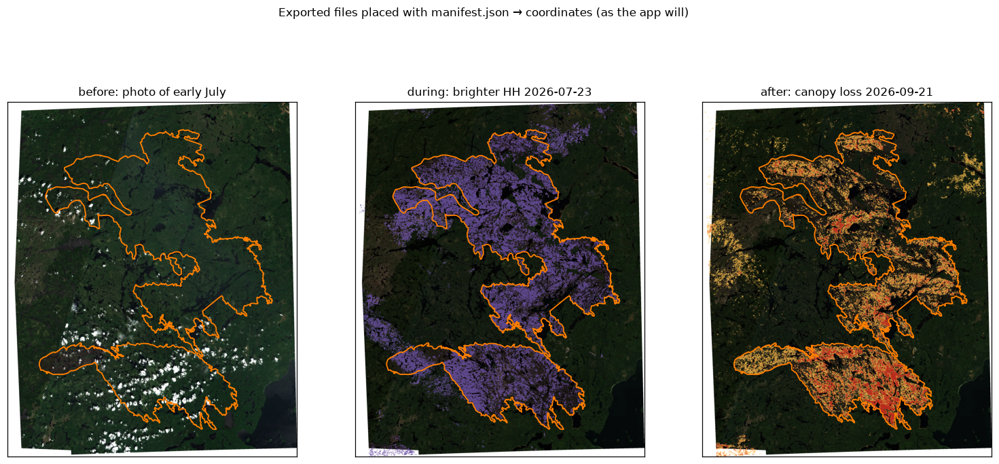

In [24]:
m = json.loads((OUT / "manifest.json").read_text())
x = json.loads((OUT / "extra.json").read_text())
CASE_STUDY_FIELDS = {"case", "title", "event_date", "story", "method", "limitations", "coordinates", "image_crs", "satellite",
                     "sources", "key_dates", "scene", "layers", "pairs", "stages"}
assert set(m) == CASE_STUDY_FIELDS, f"fields differ from CaseStudy: {set(m) ^ CASE_STUDY_FIELDS}"
assert [s["type"] for s in m["stages"]] == ["leadUp", "event", "takeaway"]
named = list(m["scene"].values()) + [l["file"] for l in m["layers"]] + [p[k] for p in m["pairs"] for k in ("file", "file_brighter")] \
        + [s["imagery"] for s in m["stages"]]
assert all(f.count("/") == 1 for f in named), "paths must be flat: case5/<file>"
missing = [f for f in named if not (OUT / f.removeprefix(FOLDER + "/")).exists()]
assert not missing, f"files named in the manifest but missing: {missing}"

files_out = sorted(p for p in OUT.rglob("*") if p.is_file())
assert all(p.parent == OUT for p in files_out), "the export folder must be flat"
print(f"{len(files_out)} files, {sum(p.stat().st_size for p in files_out) / 1e6:.1f} MB; flat; every file named in manifest.json exists")

for key, colors in (("file", BURN_COLORS.values()), ("file_brighter", [BRIGHT_COLOR])):
    allowed = {tuple(int(c[i:i + 2], 16) for i in (1, 3, 5)) for c in colors}
    for p in m["pairs"]:
        img = np.asarray(Image.open(OUT / p[key].removeprefix(FOLDER + "/")))
        used = {tuple(px[:3]) for px in np.unique(img[img[..., 3] > 0].reshape(-1, 4), axis=0)}
        assert used <= allowed, f"unexpected colours in {p[key]}"
v = rioxarray.open_rasterio(OUT / x["files"]["radar_values"][AFTER].removeprefix(FOLDER + "/")).values[0].astype(float)
back = np.where(v == NODATA, np.nan, VALUE_OFFSET + VALUE_STEP * v)
print(f"value raster round trip: max error {np.nanmax(np.abs(back - coarser(CLEAN.HV.sel(date=AFTER)).values)):.3f} dB")

w, s, e, n = m["coordinates"]
(x0, x1), (y0, y1) = Transformer.from_crs(4326, WEB, always_xy=True).transform([w, e], [s, n])
fig, axes = plt.subplots(1, 3, figsize=(17, 7.5))
for ax, photo_path, stage, title in ((axes[0], m["scene"]["imagery"], None, "before: photo of early July"),
                                     (axes[1], m["scene"]["imagery_after"], m["stages"][1], f"during: brighter HH {EVENT_PASS}"),
                                     (axes[2], m["scene"]["imagery_after"], m["stages"][2], f"after: canopy loss {AFTER}")):
    ax.imshow(Image.open(OUT / photo_path.removeprefix(FOLDER + "/")), extent=[x0, x1, y0, y1])
    if stage:
        ax.imshow(Image.open(OUT / stage["imagery"].removeprefix(FOLDER + "/")), extent=[x0, x1, y0, y1], alpha=0.85)
    gpd.read_file(OUT / m["scene"]["perimeter"].removeprefix(FOLDER + "/")).to_crs(WEB).boundary.plot(ax=ax, color="#ff7f00", lw=1.2)
    clean_axes(ax, title)
plt.suptitle("Exported files placed with manifest.json → coordinates (as the app will)")
plt.show()